# Notebook 04 — Interpreting the Plot-Similarity Network

**Job of this notebook:** say what the narrative communities found in Notebook 03 *are*, which films hold the network together and which films sit between communities. It also produces the labels every later notebook and brick uses.

**Reading rule:** centrality is a position in the plot-similarity network, not fame or quality. A film is central when many films have similar overviews.

### Design decisions
| # | Decision | Why it matters |
|---|----------|----------------|
| 1 | Built on the **consensus communities and exact betweenness** of NB03. Every film carries its **membership confidence**; every community its **robustness**. A community with robustness below 0.5 is marked *tentative*. | Interpretations rest on boundaries that do not depend on one random seed. |
| 2 | **Representative films are ranked by within-community strength** (similarity to films of the *same* community), core films first (core = ≥ 75% of a film's similarity stays inside its community). Global weighted degree would also reward films whose neighbours are in other communities. | The films used to name a community actually belong to it. |
| 3 | **Bridges are described, not just ranked:** exact betweenness plus the **participation coefficient** (Guimerà & Amaral, 2005) and the two communities each bridge connects. | "Bridge film" becomes a measured claim: *between which narratives*. |
| 4 | **Evidence for labelling:** distinctive words per community (class-based TF-IDF on the overviews), recurring character/franchise names, genre composition, a map of which communities border which. | Labels are justified by the plots themselves, not only by a few titles. |
| 5 | **Are communities just genres?** Normalised mutual information between community and genre, with a composition heatmap. | Directly answers the obvious examiner question. |
| 6 | **Labelling workflow without copy-paste:** labels carried over by NB03 are pre-filled; one file is edited (`community_labels_v2_manual.csv`), and the labelled file the bricks read is written only when every major community has a reviewed label. A labelled file left over from an earlier network is detected, never silently used. | No stale labels reach the bricks. |
| 7 | One `CFG`, a safe Drive mount, vectorised code (no per-community loops), title families computed once, a word-bounded event check (so `TNA` does not match *Vietnam*). | Reliability and speed. |

**Files the bricks read keep stable names and columns** (new columns are added at the end): `top_visible_central_films_per_community.csv`, `top_weighted_degree_raw.csv`, `top_weighted_degree_franchise_capped.csv`, `top_weighted_degree_visible_franchise_capped.csv`, `top_betweenness_visible_franchise_capped.csv`, `bridging_films_betweenness.csv`, `community_manual_labeling_template_labeled.csv`. Other tables and figures go to `outputs/tables/interpretation/` and `outputs/figures/interpretation/`.

In [1]:
# ═══════════════════════════════════════════════════════════════════════════
# CELL 1 — CONFIG
# ═══════════════════════════════════════════════════════════════════════════
CFG = {
    "project_dir": "/content/drive/MyDrive/thesis_movie_project",

    # ── what counts as interpretable ─────────────────────────────────────────
    "min_community_size_for_interpretation": 100,   # "major" communities get labels
    "display_min_vote_count": 50,                   # films shown as examples must be recognisable
    "core_internal_share": 0.75,                    # core film: ≥ 75% of its similarity stays inside its community
    "boundary_confidence": 0.20,                    # boundary film: in its community in < 20% of single Louvain runs
    "tentative_robustness": 0.50,                   # community robustness < this = tentative community
    # a community is "franchise/name-driven" when one title family or one character name dominates it
    # (real data: Scooby-Doo, Harry Potter, Madea, Chucky, Death Race, Lupin/Leprechaun, Coco Chanel, Oscar Wilde …)
    "franchise_family_share": 0.25,                 # largest title family ≥ this share of the community's films
    "name_film_share": 0.40,                        # top character/franchise name appears in ≥ this share of its overviews

    # ── table sizes ──────────────────────────────────────────────────────────
    "top_n_global": 50,
    "top_n_bridges": 100,
    "top_n_per_community": 10,
    "top_n_per_community_display": 3,               # rows per community in top_visible_central_films_per_community
    "n_peripheral": 100,

    # ── how representative films are chosen ──────────────────────────────────
    "central_metric": "within_community_strength",  # or "weighted_degree"
    "core_first": True,                             # within a community, list core films before boundary films

    # ── distinctive words per community (needs df_network_corpus.csv for the overviews) ──
    "key_terms": True,
    "key_terms_n": 12,
    "key_terms_min_df": 5,
    "key_terms_max_df": 0.40,
    "separate_names": True,          # character names and places are reported apart from theme words
    "use_spacy_ner": True,           # spaCy PERSON / GPE tags decide what is a name (fallback: capitalisation rule)
    "name_capital_share": 0.90,
    "well_known_min_votes": 1000,    # "well-known examples" column in the labelling evidence

    # ── labels ───────────────────────────────────────────────────────────────
    "require_review_before_export": True,   # each major label needs label_reviewed = yes in the labels file …
    "accept_all_labels": False,             # … or set this to True once you have read ALL labels and accept them as they are

    # ── display-only franchise cap (never changes the network) ───────────────
    "franchise_patterns": {
        "scooby_doo": r"scooby[\s\-]*doo|\bscoob\b", "star_wars": r"star\s+wars",
        "harry_potter": r"harry\s+potter|fantastic\s+beasts", "lord_of_the_rings": r"lord\s+of\s+the\s+rings|hobbit",
        "batman": r"\bbatman\b|dark\s+knight", "superman": r"\bsuperman\b", "spider_man": r"spider[\s\-]*man",
        "x_men": r"\bx[\s\-]*men\b|wolverine", "avengers": r"\bavengers\b",
        "fast_furious": r"fast\s+.*furious|fast\s+five|fast\s+x", "mission_impossible": r"mission[\s:]*impossible",
        "james_bond": r"james\s+bond|007", "jurassic": r"jurassic\s+park|jurassic\s+world",
        "godzilla": r"\bgodzilla\b", "king_kong": r"king\s+kong", "pokemon": r"pok[eé]mon", "naruto": r"\bnaruto\b",
        "dragon_ball": r"dragon\s+ball", "one_piece": r"one\s+piece", "detective_conan": r"detective\s+conan|case\s+closed",
        "barbie": r"\bbarbie\b", "cinderella": r"\bcinderella\b", "snow_white": r"snow\s+white",
        "alice_wonderland": r"alice\s+.*wonderland", "christmas_carol": r"christmas\s+carol",
        "sherlock_holmes": r"sherlock\s+holmes", "zorro": r"\bzorro\b",
    },
    # word-bounded, so "TNA" does not match "Vietnam"
    "event_title_pattern": r"\b(?:WWE|WWF|WCW|NXT|AEW|TNA|Impact Wrestling|WrestleMania|Royal Rumble|SummerSlam|"
                           r"Survivor Series|UFC|Bellator|ONE Championship|Pride FC)\b",
    "figure_dpi": 200,
    "label_chars_in_figures": 42,    # long labels are shortened at a word boundary ("…")
}
print("CONFIG loaded.")


CONFIG loaded.


In [2]:
# ═══════════════════════════════════════════════════════════════════════════
# CELL 2 — Imports, Drive mount (idempotent), paths, figure style, helpers
# ═══════════════════════════════════════════════════════════════════════════
import json, re, hashlib, warnings
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from scipy.stats import kruskal
from sklearn.metrics import normalized_mutual_info_score, adjusted_rand_score

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_colwidth", 110)
try:
    display
except NameError:
    display = print

import os, shutil, time
def mount_drive():
    """Mount Google Drive in Colab. Safe to re-run."""
    try:
        from google.colab import drive
    except ImportError:
        print("Not running in Colab — using local paths.")
        return
    if os.path.ismount("/content/drive"):          # a real Drive mount, not just a folder with that name
        print("Google Drive already mounted.")
        return
    # A plain folder at /content/drive (created while Drive was not connected) hides your Drive and blocks
    # mounting ("Mountpoint must not already contain files"). Move it aside — nothing on Drive is touched.
    if os.path.isdir("/content/drive") and os.listdir("/content/drive"):
        aside = f"/content/drive_local_leftover_{time.strftime('%Y%m%d_%H%M%S')}"
        shutil.move("/content/drive", aside)
        print(f"Moved a local leftover folder (not your Drive) to {aside}.")
    drive.mount("/content/drive")
mount_drive()

PROJECT_DIR = Path(CFG["project_dir"])
if not PROJECT_DIR.exists():
    raise FileNotFoundError(f"Project folder not found: {PROJECT_DIR}. Check that Google Drive is mounted "
                            "(left sidebar → Files → drive/MyDrive) and that CFG['project_dir'] is right.")
CORE_DIR    = PROJECT_DIR / "processed" / "core"
NETWORK_DIR = PROJECT_DIR / "processed" / "network"
TABLES_DIR  = PROJECT_DIR / "outputs" / "tables"            # files the bricks read
FIG_DIR     = PROJECT_DIR / "outputs" / "figures"
INT_TABLES  = TABLES_DIR / "interpretation"                 # new tables
INT_FIGS    = FIG_DIR / "interpretation"                    # new figures
for d in [TABLES_DIR, FIG_DIR, INT_TABLES, INT_FIGS]:
    d.mkdir(parents=True, exist_ok=True)

NODES_FILE    = NETWORK_DIR / "semantic_network_nodes_lcc.csv"
EDGES_FILE    = NETWORK_DIR / "semantic_network_edges_mutual_knn.csv"
SUMMARY_FILE  = NETWORK_DIR / "community_summary.csv"
AUDIT_FILE    = TABLES_DIR / "network_audit.csv"
MANIFEST_FILE = NETWORK_DIR / "network_manifest.json"
CORPUS_FILE   = CORE_DIR / "df_network_corpus.csv"
DRAFT_FILE    = TABLES_DIR / "community_labels_draft_v2.csv"       # from NB03 (label carry-over)
MANUAL_FILE   = TABLES_DIR / "community_labels_v2_manual.csv"      # the ONE file you edit
LABELED_FILE  = TABLES_DIR / "community_manual_labeling_template_labeled.csv"   # read by the bricks

# ── one figure style for all notebooks (validated colour-blind-safe palette) ──
INK, INK_2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
DIVERGING = "RdBu_r"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlepad": 24,
    "axes.labelsize": 10, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "text.color": INK, "font.family": "DejaVu Sans", "lines.linewidth": 2, "legend.frameon": False,
})

def subtitle(ax, text):
    # fixed offset in points (not a fraction of the axes), so tall figures do not push it into the title
    ax.annotate(text, xy=(0, 1), xycoords="axes fraction", xytext=(0, 6), textcoords="offset points",
                fontsize=9.5, color=INK_2, va="bottom", ha="left")

import textwrap
def short(text, n=None):
    return textwrap.shorten(str(text), width=n or CFG["label_chars_in_figures"], placeholder="…")

def save(fig, table, name, also_v1=None):
    """Every new figure is saved with the table that holds its numbers."""
    fig.savefig(INT_FIGS / f"{name}.png", dpi=CFG["figure_dpi"], bbox_inches="tight")
    if also_v1:
        fig.savefig(FIG_DIR / also_v1, dpi=CFG["figure_dpi"], bbox_inches="tight")
    table.to_csv(INT_TABLES / f"{name}.csv", index=False)
    plt.show()
    print(f"  ✓ figures/interpretation/{name}.png + tables/interpretation/{name}.csv"
          + (f"  ✓ figures/{also_v1}" if also_v1 else ""))

def save_v1(df, name):
    df.to_csv(TABLES_DIR / name, index=False)
    print(f"  ✓ tables/{name}")

def save_new(df, name):
    df.to_csv(INT_TABLES / name, index=False)
    print(f"  ✓ tables/interpretation/{name}")

def fingerprint(values):
    return hashlib.sha256(",".join(pd.Series(values).astype(str)).encode()).hexdigest()[:16]

def is_blank(s):
    return s.fillna("").astype(str).str.strip().isin(["", "nan", "None"])

print("PROJECT_DIR:", PROJECT_DIR)


Google Drive already mounted.
PROJECT_DIR: /content/drive/MyDrive/thesis_movie_project


## 1. Load the network and check it is the one Notebook 03 wrote

In [4]:
# ═══════════════════════════════════════════════════════════════════════════
# CELL 3 — Load network outputs (required files stop the notebook, optional ones are skipped)
# ═══════════════════════════════════════════════════════════════════════════
required = {"nodes": NODES_FILE, "edges": EDGES_FILE, "community_summary": SUMMARY_FILE}
missing = [k for k, p in required.items() if not p.exists()]
if missing:
    print("Looked in:", NETWORK_DIR)
    print("Folder exists:", NETWORK_DIR.exists())
    if NETWORK_DIR.exists():
        print("It contains:", sorted(p.name for p in NETWORK_DIR.iterdir())[:30])
    raise FileNotFoundError(
        f"Missing: {missing}. Run Notebook 03 first (or wait until it has finished).")

nodes = pd.read_csv(NODES_FILE)
edges = pd.read_csv(EDGES_FILE)
community_summary = pd.read_csv(SUMMARY_FILE)
network_audit = pd.read_csv(AUDIT_FILE) if AUDIT_FILE.exists() else pd.DataFrame(columns=["metric", "value"])
manifest = json.loads(MANIFEST_FILE.read_text()) if MANIFEST_FILE.exists() else None
print(f"nodes {nodes.shape} · edges {edges.shape} · communities {nodes['community_id'].nunique()}")

# ── which network is this? ───────────────────────────────────────────────────
IS_V2 = {"membership_confidence", "betweenness_centrality"} <= set(nodes.columns)
BETW = "betweenness_centrality" if "betweenness_centrality" in nodes else "betweenness_centrality_sampled"
HAS_CONF = IS_V2 and nodes["membership_confidence"].notna().any()
audit = network_audit.set_index("metric")["value"] if len(network_audit) else pd.Series(dtype=object)
print("Network version:", "consensus communities, exact betweenness" if IS_V2
      else "single Louvain, sampled betweenness — confidence-based parts are skipped")
print("Community method:", audit.get("community_method", "unknown"), "· betweenness:", audit.get("betweenness_method", BETW))
if manifest:
    ok = manifest.get("nodes_fingerprint") == fingerprint(nodes["tmdb_id"])
    print("Matches network_manifest.json:", ok)
    if not ok:
        print("⚠ The node file changed after Notebook 03 wrote its manifest — re-run Notebook 03.")

# ── one id → community lookup, used everywhere below ─────────────────────────
nodes["community_id"] = nodes["community_id"].astype(int)
comm_of = nodes.set_index("node_id")["community_id"]
sizes = nodes["community_id"].value_counts()
MAJOR = sizes[sizes >= CFG["min_community_size_for_interpretation"]].index.tolist()   # largest first
PARTITION_FP = fingerprint(nodes.sort_values("tmdb_id")[["tmdb_id", "community_id"]].astype(str).agg(":".join, axis=1))
print(f"Major communities (≥ {CFG['min_community_size_for_interpretation']} films): {len(MAJOR)} "
      f"covering {sizes[MAJOR].sum() / len(nodes):.1%} of films · partition fingerprint {PARTITION_FP}")


nodes (19084, 33) · edges (70252, 9) · communities 105
Network version: v2 (consensus communities, exact betweenness)
Community method: consensus_louvain_igraph · betweenness: exact_igraph
Matches network_manifest.json: True
Major communities (≥ 100 films): 35 covering 93.2% of films · partition fingerprint ed95a1e267a9e3ef


### What changed since the previous network?

If Notebook 04 already ran on an earlier network (for example the one built before character names were masked), its film positions are still on Drive. This cell compares the two partitions before they are overwritten: how similar they are, how many films left or joined the largest component, and what happened to the communities that were held together by one character name.

In [5]:
# ═══════════════════════════════════════════════════════════════════════════
# CELL 3b — Compare with the previous network (e.g. before name masking)
# ═══════════════════════════════════════════════════════════════════════════
PREV_POS = NETWORK_DIR / "node_positions_nb04.csv"
PREV_FD = INT_TABLES / "franchise_or_name_driven_communities.csv"
change = None
if PREV_POS.exists():
    prev = pd.read_csv(PREV_POS, usecols=["tmdb_id", "community_id"]).rename(columns={"community_id": "prev_cid"})
    if fingerprint(prev.sort_values("tmdb_id").astype(str).agg(":".join, axis=1)) != PARTITION_FP:
        both_ = prev.merge(nodes[["tmdb_id", "community_id"]], on="tmdb_id")
        rows = [("films in previous network", len(prev)), ("films in current network", len(nodes)),
                ("films in both", len(both_)),
                ("films that left the network", int((~prev["tmdb_id"].isin(nodes["tmdb_id"])).sum())),
                ("films that joined the network", int((~nodes["tmdb_id"].isin(prev["tmdb_id"])).sum())),
                ("previous communities", prev["prev_cid"].nunique()), ("current communities", nodes["community_id"].nunique()),
                ("ARI previous vs current (films in both)", round(adjusted_rand_score(both_["prev_cid"], both_["community_id"]), 3)),
                ("NMI previous vs current (films in both)", round(normalized_mutual_info_score(both_["prev_cid"], both_["community_id"]), 3))]
        if PREV_FD.exists():
            fd_prev = pd.read_csv(PREV_FD)
            if "name_driven" in fd_prev:
                nd = fd_prev.loc[fd_prev["name_driven"].astype(bool), "community_id"]
                spread = (both_[both_["prev_cid"].isin(nd)].groupby("prev_cid")["community_id"]
                          .agg(lambda x: x.value_counts(normalize=True).iloc[0]))
                rows += [("previous name-driven communities", len(nd)),
                         ("… mean share of their films still together in one community", round(spread.mean(), 3))]
        change = pd.DataFrame(rows, columns=["measure", "value"]).astype({"value": object})
        display(change)
        save_new(change, "change_vs_previous_network.csv")
        prev_copy = NETWORK_DIR / "node_positions_nb04_previous.csv"
        PREV_POS.replace(prev_copy)
        print(f"  ✓ previous positions kept as processed/network/{prev_copy.name}")
    else:
        print("Same communities as the previous Notebook 04 run.")
else:
    print("No previous Notebook 04 run to compare with.")


Same communities as the previous Notebook 04 run.


In [6]:
# ═══════════════════════════════════════════════════════════════════════════
# CELL 4 — Basic checks and event contamination 
# ═══════════════════════════════════════════════════════════════════════════
basic_checks = pd.DataFrame([
    {"check": "n_nodes", "value": len(nodes)},
    {"check": "n_edges", "value": len(edges)},
    {"check": "n_communities", "value": nodes["community_id"].nunique()},
    {"check": "n_major_communities", "value": len(MAJOR)},
    {"check": "min_year", "value": nodes["release_year"].min()},
    {"check": "max_year", "value": nodes["release_year"].max()},
    {"check": "median_vote_count", "value": nodes["vote_count"].median()},
    {"check": "median_overview_word_count", "value": nodes["overview_word_count"].median()},
    {"check": "revenue_available_pct", "value": round(nodes["revenue_clean"].notna().mean() * 100, 2)},
    {"check": "edges_with_unknown_node", "value": int((~edges["source_node_id"].isin(comm_of.index)
                                                       | ~edges["target_node_id"].isin(comm_of.index)).sum())},
    {"check": "duplicate_tmdb_id", "value": int(nodes["tmdb_id"].duplicated().sum())},
])
if HAS_CONF:
    basic_checks.loc[len(basic_checks)] = ["median_membership_confidence", nodes["membership_confidence"].median()]
display(basic_checks)
save_v1(basic_checks, "network_interpretation_basic_checks.csv")

event_check = nodes[nodes["title"].fillna("").str.contains(CFG["event_title_pattern"], case=False, regex=True)]
print(f"Titles with a wrestling/MMA brand left in the network: {len(event_check)}")
if len(event_check):
    print("  These are story films kept on purpose by Notebook 01 (animated/family crossovers such as "
          "'Scooby-Doo! WrestleMania Mystery'), not recorded events. Check the list once.")
display(event_check[["title", "release_year", "primary_genre", "vote_count", "community_id"]].head(20))
save_v1(event_check, "remaining_event_like_titles_check.csv")


,check,value
0,n_nodes,19084.000
1,n_edges,70252.000
2,n_communities,105.000
3,n_major_communities,35.000
4,min_year,1990.000
5,max_year,2024.000
6,median_vote_count,96.000
7,median_overview_word_count,57.000
8,revenue_available_pct,39.550
9,edges_with_unknown_node,0.000


  ✓ tables/network_interpretation_basic_checks.csv
Titles with a wrestling/MMA brand left in the network: 3
  These are story films kept on purpose by Notebook 01 (animated/family crossovers such as 'Scooby-Doo! WrestleMania Mystery'), not recorded events. Check the list once.


,title,release_year,primary_genre,vote_count,community_id
12650,Scooby-Doo! WrestleMania Mystery,2014,Animation,331.0,41
15332,Scooby-Doo! and WWE: Curse of the Speed Demon,2016,Animation,199.0,41
17155,The Jetsons & WWE: Robo-WrestleMania,2017,Animation,57.0,5


  ✓ tables/remaining_event_like_titles_check.csv


## 2. Where each film sits: within-community strength and participation

For every film, its edge weights (cosine similarities) are split by the community of each neighbour:
* **within-community strength** — total similarity to films of its own community; the basis for choosing representative films;
* **participation coefficient** *P* = 1 − Σ<sub>s</sub>(k<sub>is</sub>/k<sub>i</sub>)² — 0 when all neighbours are in one community, higher when they are spread over several (Guimerà & Amaral, 2005);
* **main external community** — where most of its outside similarity goes.

For each community: the share of its members' similarity that stays inside (**cohesion**) and mean similarity of internal vs boundary edges.

In [7]:
# ═══════════════════════════════════════════════════════════════════════════
# CELL 5 — Film-level position and community cohesion (vectorised over the edge list)
# ═══════════════════════════════════════════════════════════════════════════
e = edges[["source_node_id", "target_node_id", "cosine_similarity"]].rename(
    columns={"source_node_id": "a", "target_node_id": "b", "cosine_similarity": "w"})
e["ca"], e["cb"] = e["a"].map(comm_of), e["b"].map(comm_of)
e = e.dropna(subset=["ca", "cb"]).astype({"ca": int, "cb": int})
e["internal"] = e["ca"] == e["cb"]

# both directions: every film sees each neighbour's community
both = pd.concat([e[["a", "cb", "w"]].set_axis(["node_id", "nbr_comm", "w"], axis=1),
                  e[["b", "ca", "w"]].set_axis(["node_id", "nbr_comm", "w"], axis=1)], ignore_index=True)
k_is = both.groupby(["node_id", "nbr_comm"])["w"].sum().reset_index()
k_is["own"] = k_is["nbr_comm"].values == k_is["node_id"].map(comm_of).values
k_i = k_is.groupby("node_id")["w"].sum()
k_is["share"] = k_is["w"] / k_is["node_id"].map(k_i)

position = pd.DataFrame({
    "within_community_strength": k_is[k_is["own"]].groupby("node_id")["w"].sum(),
    "participation_coefficient": 1 - (k_is["share"] ** 2).groupby(k_is["node_id"]).sum(),
})
ext = k_is[~k_is["own"]].sort_values(["node_id", "w"], ascending=[True, False]).drop_duplicates("node_id")
position["main_external_community"] = ext.set_index("node_id")["nbr_comm"]
position["external_share"] = 1 - position["within_community_strength"].fillna(0) / k_i
nodes = nodes.drop(columns=[c for c in position.columns if c in nodes.columns]).merge(
    position, left_on="node_id", right_index=True, how="left")
nodes["within_community_strength"] = nodes["within_community_strength"].fillna(0)
nodes["main_external_community"] = nodes["main_external_community"].astype("Int64")
# core film: most of its plot similarity stays inside its own community (structural, per film).
# Membership confidence is NOT used for this: it measures whether single Louvain runs keep the film's whole
# community together, so films of a community that single runs split in two all get the same value.
nodes["is_core"] = (1 - nodes["external_share"]) >= CFG["core_internal_share"]
nodes["is_boundary"] = (nodes["membership_confidence"] < CFG["boundary_confidence"]) if HAS_CONF else False

# ── community cohesion ───────────────────────────────────────────────────────
strength_by_comm = nodes.groupby("community_id")[["within_community_strength"]].sum()
strength_by_comm["total_strength"] = nodes.assign(k=nodes["node_id"].map(k_i)).groupby("community_id")["k"].sum()
w_int = e[e["internal"]].groupby("ca")["w"].mean()
w_bnd = pd.concat([e.loc[~e["internal"], ["ca", "w"]].rename(columns={"ca": "c"}),
                   e.loc[~e["internal"], ["cb", "w"]].rename(columns={"cb": "c"})]).groupby("c")["w"].mean()
cohesion = pd.DataFrame({
    "cohesion_internal_share": strength_by_comm["within_community_strength"] / strength_by_comm["total_strength"],
    "mean_internal_similarity": w_int, "mean_boundary_similarity": w_bnd,
}).rename_axis("community_id").reset_index()
cohesion = cohesion.merge(nodes.groupby("community_id").agg(core_share=("is_core", "mean")).reset_index(),
                          on="community_id")
if HAS_CONF:
    cohesion = cohesion.merge(nodes.groupby("community_id").agg(
        community_robustness=("membership_confidence", "mean"),
        boundary_share=("is_boundary", "mean")).reset_index(), on="community_id")
POSITIONS_FILE = NETWORK_DIR / "node_positions_nb04.csv"     # for Notebook 05 (merge on tmdb_id)
nodes["community_group"] = np.where(nodes["community_id"].isin(MAJOR), nodes["community_id"].astype(str), "minor")
nodes[["node_id", "tmdb_id", "community_id", "community_group", "within_community_strength", "participation_coefficient",
       "main_external_community", "external_share"]].to_csv(POSITIONS_FILE, index=False)
print(f"  ✓ processed/network/{POSITIONS_FILE.name}")
print(f"Edges inside a community: {e['internal'].mean():.1%} · "
      f"mean similarity inside {e.loc[e['internal'], 'w'].mean():.3f} vs between {e.loc[~e['internal'], 'w'].mean():.3f}")
display(cohesion.sort_values("cohesion_internal_share").head(8).round(3))


  ✓ processed/network/node_positions_nb04.csv
Edges inside a community: 69.3% · mean similarity inside 0.571 vs between 0.554


,community_id,cohesion_internal_share,mean_internal_similarity,mean_boundary_similarity,core_share,community_robustness,boundary_share
75,75,0.327,0.599,0.574,0.000,0.827,0.0
88,88,0.372,0.526,0.518,0.167,1.000,0.0
104,104,0.388,0.567,0.559,0.400,0.947,0.0
60,60,0.398,0.582,0.572,0.231,0.786,0.0
97,97,0.399,0.539,0.508,0.000,0.883,0.0
95,95,0.434,0.572,0.542,0.200,1.000,0.0
100,100,0.439,0.534,0.512,0.000,1.000,0.0
51,51,0.444,0.579,0.565,0.083,0.713,0.0


In [8]:
# ═══════════════════════════════════════════════════════════════════════════
# CELL 6 — Title families (display-only franchise cap) and franchise concentration
# ═══════════════════════════════════════════════════════════════════════════
def title_family(titles):
    """Vectorised title-family matcher (verified on test titles)."""
    raw = titles.fillna("").astype(str).str.lower().str.strip()
    fam = pd.Series(np.nan, index=raw.index, dtype=object)
    for family, pattern in CFG["franchise_patterns"].items():        # first matching pattern wins
        fam = fam.mask(fam.isna() & raw.str.contains(pattern, regex=True), family)
    t = (raw.str.replace(r"['’]s\b", "", regex=True)
            .str.replace(r"[^a-z0-9\s]", " ", regex=True)
            .str.replace(r"\b(the|a|an)\b", " ", regex=True)
            .str.replace(r"\b(part|chapter|episode|vol|volume|season|book|movie|film|return|revenge|rise|fall|curse|legend)\b\s*[ivx0-9]*", " ", regex=True)
            .str.replace(r"\b[ivx]{1,5}\b", " ", regex=True)
            .str.replace(r"\b\d{1,4}\b", " ", regex=True)
            .str.replace(r"\s+", " ", regex=True).str.strip())
    t = t.mask(t == "", raw)
    return fam.fillna(t)

nodes["title_family"] = title_family(nodes["title"])
nodes["visible"] = nodes["vote_count"].fillna(0) >= CFG["display_min_vote_count"]
print("Unique title families:", nodes["title_family"].nunique(), "of", len(nodes), "films")

franchise_concentration = (nodes.groupby("title_family")
    .agg(n_titles=("title", "count"),
         example_titles=("title", lambda x: "; ".join(x.dropna().astype(str).head(8))),
         communities=("community_id", lambda x: "; ".join(map(str, sorted(x.dropna().unique())[:8]))),
         n_communities=("community_id", "nunique"),
         median_vote_count=("vote_count", "median"), max_weighted_degree=("weighted_degree", "max"))
    .reset_index().sort_values(["n_titles", "max_weighted_degree"], ascending=[False, False]))
display(franchise_concentration.head(15))
save_v1(franchise_concentration, "franchise_concentration_diagnostic.csv")

fam_counts = nodes.groupby(["community_id", "title_family"]).size().rename("n").reset_index() \
                   .sort_values(["community_id", "n"], ascending=[True, False]).drop_duplicates("community_id")
family_dominance = pd.DataFrame({
    "community_id": fam_counts["community_id"].values,
    "largest_title_family": np.where(fam_counts["n"].values > 1, fam_counts["title_family"].values, ""),
    "largest_title_family_share": (fam_counts["n"].values / fam_counts["community_id"].map(
        nodes["community_id"].value_counts()).values).round(3)})
family_dominance.loc[family_dominance["largest_title_family"] == "", "largest_title_family_share"] = 0.0
multi = franchise_concentration[franchise_concentration["n_titles"] >= 3]
print(f"Title families with ≥ 3 films: {len(multi)}; "
      f"{(multi['n_communities'] == 1).mean():.0%} of them sit entirely in one community "
      "(franchises are pulled together by shared names and plots).")


Unique title families: 17458 of 19084 films


,title_family,n_titles,example_titles,communities,n_communities,median_vote_count,max_weighted_degree
13606,scooby_doo,40,Scooby-Doo on Zombie Island; Scooby-Doo; Scooby-Doo and the Cyber Chase; Scooby-Doo 2: Monsters Unleashed;...,5; 34; 41,3,213.0,14.269744
1356,barbie,26,Barbie in the Nutcracker; Barbie as Rapunzel; Barbie as The Princess & the Pauper; Barbie: Fairytopia; Bar...,2; 5; 6; 7; 11; 12; 14; 17,11,562.5,11.090327
4154,detective_conan,26,Detective Conan: The Time Bombed Skyscraper; Detective Conan: The Private Eyes' Requiem; Case Closed: The ...,2; 3; 8; 12; 14; 24,6,151.5,8.521335
1388,batman,23,Batman Returns; Batman: Mask of the Phantasm; Batman Forever; Batman & Robin; Batman: Mystery of the Batwo...,4; 5; 21,3,703.0,10.728821
3021,cinderella,18,A Chinese Odyssey Part Two: Cinderella; Cinderella II: Dreams Come True; Cinderella; Three Wishes for Cind...,1; 2; 6; 9; 12; 15; 16; 17,10,218.0,11.482702
12339,pokemon,17,Pokémon 3: The Movie; Pokémon 4Ever; Pokémon Heroes; Pokémon: Jirachi - Wish Maker; Pokémon: Lucario and t...,4; 6; 17; 42,4,290.0,7.267321
6270,godzilla,16,Godzilla vs. King Ghidorah; Godzilla vs. Mothra; Godzilla vs. Mechagodzilla II; Godzilla vs. Destoroyah; G...,4; 14,2,330.5,8.437407
10910,naruto,11,Naruto the Movie: Ninja Clash in the Land of Snow; Naruto the Movie: Legend of the Stone of Gelel; Naruto ...,8,1,603.0,8.166194
14513,spider_man,11,Spider-Man 2; Spider-Man 3; The Amazing Spider-Man; Spider-Man: No Way Home; Spider-Man: The Venom Saga; T...,0; 1; 4; 5,4,16265.0,7.605222
11641,one_piece,11,One Piece: Dead End Adventure; One Piece: Curse of the Sacred Sword; One Piece: Baron Omatsuri and the Sec...,10; 14,2,242.0,4.963499


  ✓ tables/franchise_concentration_diagnostic.csv
Title families with ≥ 3 films: 251; 12% of them sit entirely in one community (franchises are pulled together by shared names and plots).


## 3. The communities at a glance

Size, robustness (mean membership confidence of its films) and cohesion. Robust communities can be named with confidence; **tentative** ones (robustness < 0.5) are real regions of the network but with blurred borders, and the thesis should describe them as such.

In [9]:
# ═══════════════════════════════════════════════════════════════════════════
# CELL 7 — Community size overview (with robustness and cohesion)
# ═══════════════════════════════════════════════════════════════════════════
community_size_table = (nodes.groupby("community_id")
    .agg(n_films=("node_id", "count"), median_year=("release_year", "median"),
         min_year=("release_year", "min"), max_year=("release_year", "max"),
         median_vote_count=("vote_count", "median"), median_vote_average=("vote_average", "median"),
         revenue_available_pct=("revenue_clean", lambda x: round(x.notna().mean() * 100, 2)),
         top_genre=("primary_genre", lambda x: x.value_counts().index[0] if x.notna().any() else np.nan))
    .reset_index().merge(cohesion, on="community_id", how="left")
    .sort_values("n_films", ascending=False).reset_index(drop=True))
community_size_table["share_of_network_pct"] = (community_size_table["n_films"] / len(nodes) * 100).round(2)
community_size_table = community_size_table.merge(family_dominance, on="community_id", how="left")
community_size_table["is_major"] = community_size_table["community_id"].isin(MAJOR)
if HAS_CONF:
    community_size_table["tentative"] = community_size_table["community_robustness"] < CFG["tentative_robustness"]
display(community_size_table.head(25).round(3))
save_v1(community_size_table, "community_size_overview.csv")


,community_id,n_films,median_year,min_year,max_year,median_vote_count,median_vote_average,revenue_available_pct,top_genre,cohesion_internal_share,mean_internal_similarity,mean_boundary_similarity,core_share,community_robustness,boundary_share,share_of_network_pct,largest_title_family,largest_title_family_share,is_major,tentative
0,0,1700,2011.0,1990,2024,107.0,6.100,41.18,Action,0.735,0.609,0.583,0.496,0.669,0.004,8.91,fast_furious,0.003,True,False
1,1,1360,2012.0,1990,2024,87.0,6.000,40.07,Comedy,0.690,0.610,0.589,0.430,0.597,0.015,7.13,bliss,0.002,True,False
2,2,1346,2014.0,1990,2024,88.5,6.100,37.00,Drama,0.677,0.613,0.586,0.381,0.517,0.030,7.05,alice,0.001,True,False
3,3,1246,2013.0,1990,2024,95.5,6.329,42.05,Drama,0.731,0.545,0.536,0.501,0.658,0.006,6.53,admiral,0.002,True,False
4,4,1120,2013.0,1990,2024,155.5,6.100,42.41,Action,0.792,0.527,0.515,0.609,0.780,0.004,5.87,batman,0.019,True,False
5,5,1079,2013.0,1990,2024,95.0,5.700,34.01,Horror,0.690,0.583,0.559,0.413,0.519,0.014,5.65,scary,0.004,True,False
6,6,816,2012.0,1990,2024,145.0,6.400,49.75,Drama,0.715,0.551,0.534,0.464,0.669,0.004,4.28,pokemon,0.016,True,False
7,7,717,2014.0,1990,2024,91.0,6.100,31.38,Drama,0.656,0.576,0.555,0.378,0.599,0.043,3.76,gabriel rapture,0.004,True,False
8,8,699,2013.0,1990,2024,71.0,6.700,39.91,Drama,0.733,0.543,0.528,0.499,0.740,0.000,3.66,detective_conan,0.029,True,False
9,9,656,2012.0,1990,2024,110.5,6.300,44.21,Comedy,0.676,0.569,0.554,0.405,0.491,0.032,3.44,harry_potter,0.009,True,True


  ✓ tables/community_size_overview.csv


## 4. What the communities are made of

**Genre.** If communities were just genres, knowing a film's community would tell you its genre (NMI near 1). A low NMI with clearly themed communities means the plots group films *across* genre lines — the core claim of a plot-based approach.

**Words.** Class-based TF-IDF (Grootendorst, 2022) finds the words that are frequent in one community's overviews and rare elsewhere. Character names and places (spaCy named-entity recognition) are reported apart from theme words.

**Names as a confound.** Sentence embeddings react strongly to proper names: two unrelated films whose heroes are both called *Paul* can end up as neighbours. The cell measures how many edges join films that share a character name, against chance, and flags communities held together by one name.

,comparison,NMI,ARI
0,community vs primary genre,0.107,0.023
1,community vs decade,0.007,0.000
2,community vs shuffled genre (chance level),0.013,-0.000


  ✓ tables/interpretation/communities_vs_genre_nmi.csv


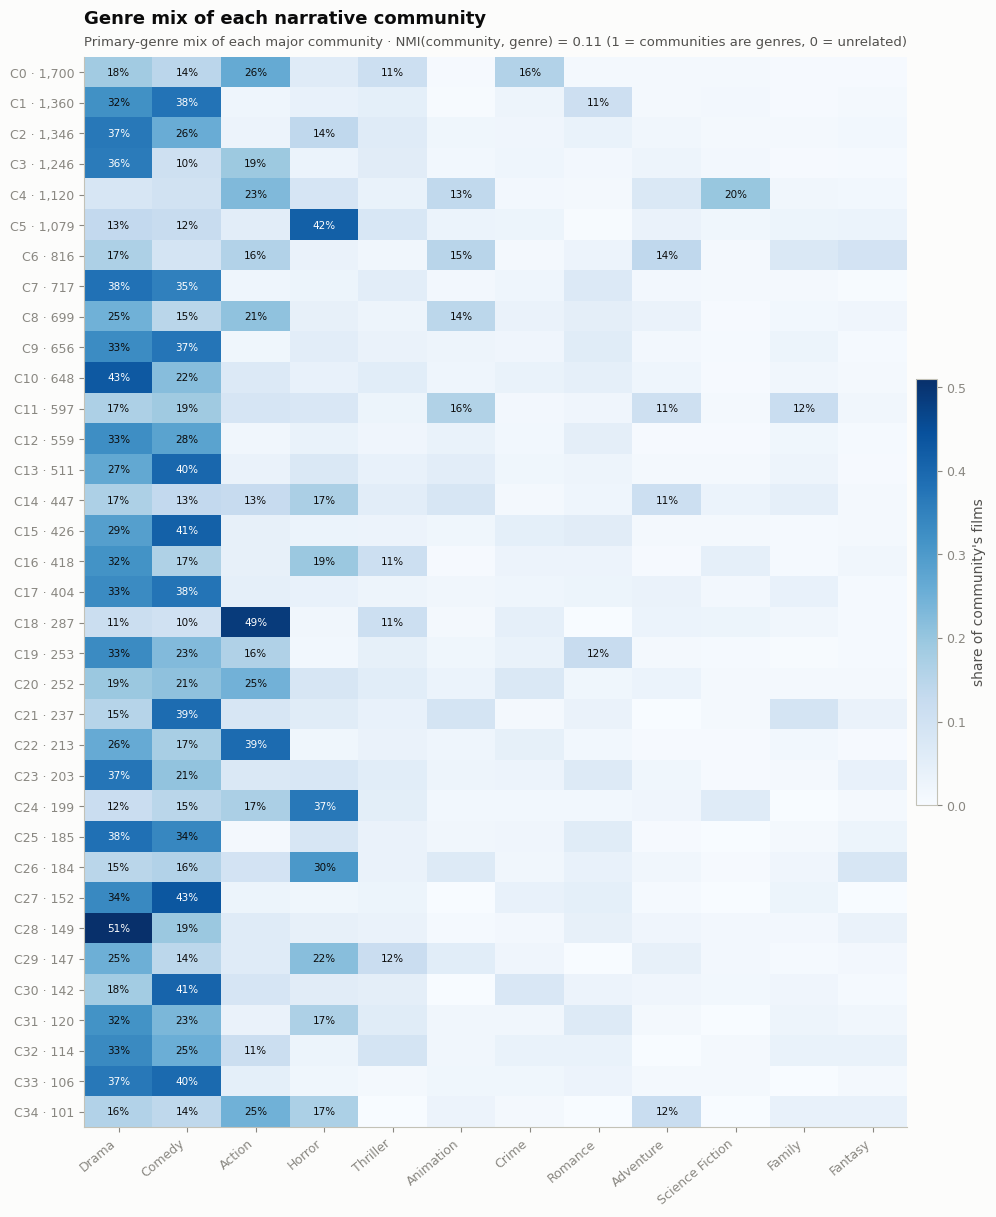

  ✓ figures/interpretation/fig_01_genre_composition.png + tables/interpretation/fig_01_genre_composition.csv


In [10]:
# ═══════════════════════════════════════════════════════════════════════════
# CELL 8 — Communities vs genres (NMI) and genre composition heatmap
# ═══════════════════════════════════════════════════════════════════════════
g = nodes.dropna(subset=["primary_genre"])
decade = (g["release_year"] // 10 * 10).astype(int)
genre_vs_comm = pd.DataFrame([
    {"comparison": "community vs primary genre", "NMI": normalized_mutual_info_score(g["primary_genre"], g["community_id"]),
     "ARI": adjusted_rand_score(g["primary_genre"], g["community_id"])},
    {"comparison": "community vs decade", "NMI": normalized_mutual_info_score(decade, g["community_id"]),
     "ARI": adjusted_rand_score(decade, g["community_id"])},
    {"comparison": "community vs shuffled genre (chance level)",
     "NMI": normalized_mutual_info_score(g["primary_genre"].sample(frac=1, random_state=42).values, g["community_id"]),
     "ARI": adjusted_rand_score(g["primary_genre"].sample(frac=1, random_state=42).values, g["community_id"])},
]).round(3)
display(genre_vs_comm)
save_new(genre_vs_comm, "communities_vs_genre_nmi.csv")

# per-community genre purity
ct = pd.crosstab(g["community_id"], g["primary_genre"])
p = ct.div(ct.sum(axis=1), axis=0)
purity = pd.DataFrame({"top_genre_share": p.max(axis=1),
                       "genre_entropy_norm": -(p * np.log(p.where(p > 0))).sum(axis=1) / np.log(p.shape[1])})
community_size_table = community_size_table.merge(purity.round(3), left_on="community_id", right_index=True, how="left")

# heatmap: major communities × most common genres (share of each community's films)
top_genres = g["primary_genre"].value_counts().head(12).index
H = p.loc[MAJOR, top_genres]
fig, ax = plt.subplots(figsize=(11, 0.34 * len(MAJOR) + 2))
im = ax.imshow(H.values, aspect="auto", cmap="Blues", vmin=0, vmax=max(0.5, H.values.max()))
ax.set_xticks(range(len(top_genres)), top_genres, rotation=40, ha="right")
ax.set_yticks(range(len(MAJOR)), [f"C{c} · {sizes[c]:,}" for c in MAJOR])
ax.grid(False)
for i in range(H.shape[0]):
    for j in range(H.shape[1]):
        v = H.values[i, j]
        if v >= 0.10:
            ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=7.5, color="white" if v > 0.35 else INK)
fig.colorbar(im, ax=ax, fraction=0.025, pad=0.01, label="share of community's films")
ax.set_title("Genre mix of each narrative community")
subtitle(ax, f"Primary-genre mix of each major community · NMI(community, genre) = "
             f"{genre_vs_comm.loc[0, 'NMI']:.2f} (1 = communities are genres, 0 = unrelated)")
save(fig, H.reset_index().rename(columns={"index": "community_id"}), "fig_01_genre_composition")


In [11]:
# ═══════════════════════════════════════════════════════════════════════════
# CELL 9 — Distinctive words, character names and places per community (class-based TF-IDF + spaCy NER)
# ═══════════════════════════════════════════════════════════════════════════
key_terms = pd.DataFrame({"community_id": sizes.index, "key_terms": "", "character_names": "", "places": ""})
name_edges = None
if CFG["key_terms"] and CORPUS_FILE.exists():
    from sklearn.feature_extraction.text import CountVectorizer
    text = nodes[["node_id", "tmdb_id", "community_id"]].merge(
        pd.read_csv(CORPUS_FILE, usecols=["tmdb_id", "overview"]), on="tmdb_id", how="left")
    docs = text["overview"].fillna("").astype(str)
    pattern = r"(?u)\b[^\W\d_]{3,}\b"
    cv = CountVectorizer(stop_words="english", token_pattern=pattern,
                         min_df=CFG["key_terms_min_df"], max_df=CFG["key_terms_max_df"])
    X = cv.fit_transform(docs)
    vocab = np.array(cv.get_feature_names_out())

    # capitalisation share of every word (a name is written with a capital almost every time)
    cv_raw = CountVectorizer(lowercase=False, token_pattern=pattern, min_df=2)
    R = np.asarray(cv_raw.fit_transform(docs).sum(axis=0)).ravel()
    raw_vocab = pd.Series(cv_raw.get_feature_names_out())
    caps = pd.DataFrame({"w": raw_vocab.str.lower(), "n": R, "cap": raw_vocab.str[0].str.isupper()})
    cap_share = caps.assign(nc=caps["n"] * caps["cap"]).groupby("w")[["nc", "n"]].sum()
    cap_share = pd.Series(vocab).map(cap_share["nc"] / cap_share["n"]).fillna(0).values
    capitalised = cap_share >= CFG["name_capital_share"]

    # people and places from spaCy NER (Colab ships spaCy; the small English model is fetched if missing)
    person_words, place_words, film_names = None, None, None
    if CFG["use_spacy_ner"]:
        try:
            import spacy
            try:
                nlp = spacy.load("en_core_web_sm", disable=["parser", "lemmatizer", "tagger", "attribute_ruler"])
            except OSError:
                from spacy.cli import download
                download("en_core_web_sm")
                nlp = spacy.load("en_core_web_sm", disable=["parser", "lemmatizer", "tagger", "attribute_ruler"])
            rows = []
            for i, d in enumerate(nlp.pipe(docs.tolist(), batch_size=256)):
                for ent in d.ents:
                    k = ("person" if ent.label_ == "PERSON" else
                         "place" if ent.label_ in ("GPE", "LOC", "NORP") else "other")   # DATE, EVENT, ORG …
                    for w in re.findall(pattern, ent.text):
                        rows.append((i, w.lower(), k))
            ents = pd.DataFrame(rows, columns=["doc", "word", "kind"]).drop_duplicates()
            kind = ents.groupby(["word", "kind"]).size().unstack(fill_value=0)
            kind = kind.reindex(columns=["person", "place", "other"], fill_value=0)
            # a word is a name only if spaCy calls it a person more often than anything else
            # (so "Christmas", usually a DATE/EVENT, is not treated as a character name)
            person_words = set(kind.index[kind["person"] > kind["place"] + kind["other"]])
            place_words = set(kind.index[kind["place"] > kind["person"] + kind["other"]])
            film_names = ents[ents["kind"] == "person"].assign(node_id=lambda d: text["node_id"].values[d["doc"]])
            print(f"spaCy NER: {len(person_words):,} name words, {len(place_words):,} place words.")
        except Exception as ex:
            print("spaCy NER unavailable, using the capitalisation rule only:", ex)
    if person_words is not None:
        is_name = capitalised & np.isin(vocab, list(person_words))
        is_place = capitalised & np.isin(vocab, list(place_words)) & ~is_name
    else:
        is_name, is_place = capitalised, np.zeros(len(vocab), dtype=bool)

    comm_codes, comm_index = pd.factorize(text["community_id"])
    M = sparse.csr_matrix((np.ones(len(docs)), (comm_codes, np.arange(len(docs)))), shape=(len(comm_index), len(docs)))
    C = (M @ X).toarray().astype(float)                                  # word counts per community
    tf = C / np.maximum(C.sum(axis=1, keepdims=True), 1)
    idf = np.log(1 + C.sum(axis=1).mean() / np.maximum(C.sum(axis=0), 1))
    ctfidf = tf * idf

    def top_words(mask, n):
        s_ = np.where(mask[None, :], ctfidf, -1)
        idx = np.argsort(-s_, axis=1)[:, :n]
        return ["; ".join(vocab[row][s_[i, row] > 0]) for i, row in enumerate(idx)]
    key_terms = pd.DataFrame({"community_id": comm_index,
                              "key_terms": top_words(~is_name & ~is_place, CFG["key_terms_n"]),
                              "character_names": top_words(is_name, 6),
                              "places": top_words(is_place, 5)})
    # how many of a community's overviews mention its most distinctive character name?
    if is_name.any():
        s_names = np.where(is_name[None, :], ctfidf, -1)
        top_idx = s_names.argmax(axis=1)
        present = (X[:, top_idx] > 0).toarray()                            # films × communities
        share = np.array([present[comm_codes == k, k].mean() for k in range(len(comm_index))])
        key_terms["top_name"] = np.where(s_names.max(axis=1) > 0, vocab[top_idx], "")
        key_terms["top_name_film_share"] = np.where(key_terms["top_name"] != "", share, 0).round(3)
    print(f"Vocabulary {len(vocab):,} words: {is_name.sum():,} names, {is_place.sum():,} places kept apart from themes.")
    display(key_terms.set_index("community_id").loc[MAJOR].head(33))

    # ── do films get linked because their overviews share a character name? ────
    if film_names is not None and len(film_names):
        fn = film_names[["node_id", "word"]].drop_duplicates()
        def share_with_name(a, b):
            pairs_ = pd.DataFrame({"a": a, "b": b, "k": np.arange(len(a))})
            hit = pairs_.merge(fn, left_on="a", right_on="node_id").merge(fn, left_on=["b", "word"],
                                                                          right_on=["node_id", "word"])
            return hit["k"].nunique() / len(a)
        obs = share_with_name(e["a"].values, e["b"].values)
        rng = np.random.default_rng(42)
        rand = share_with_name(e["a"].values, rng.permutation(e["b"].values))
        inside = share_with_name(e.loc[e["internal"], "a"].values, e.loc[e["internal"], "b"].values)
        name_edges = pd.DataFrame([
            {"measure": "edges whose two overviews share a character name", "value": round(obs, 4)},
            {"measure": "same, random film pairs (chance level)", "value": round(rand, 4)},
            {"measure": "ratio observed / chance", "value": round(obs / max(rand, 1e-9), 1)},
            {"measure": "same, edges inside a community", "value": round(inside, 4)},
        ])
        display(name_edges)
        save_new(name_edges, "edges_sharing_character_names.csv")
else:
    print("Key terms skipped (CFG['key_terms'] is False or df_network_corpus.csv is missing).")
for c, v in [("top_name", ""), ("top_name_film_share", 0.0)]:
    if c not in key_terms:
        key_terms[c] = v
save_new(key_terms, "community_key_terms.csv")

# ── franchise-driven vs character-name-driven communities ──────────────────
community_size_table = community_size_table.merge(key_terms[["community_id", "top_name", "top_name_film_share"]],
                                                  on="community_id", how="left")
community_size_table["franchise_driven"] = community_size_table["largest_title_family_share"] >= CFG["franchise_family_share"]
community_size_table["name_driven"] = community_size_table["top_name_film_share"].fillna(0) >= CFG["name_film_share"]
community_size_table["franchise_or_name_driven"] = community_size_table["franchise_driven"] | community_size_table["name_driven"]
fd = community_size_table[community_size_table["franchise_or_name_driven"]]
print(f"\nFranchise-driven: {int(community_size_table['franchise_driven'].sum())} communities · "
      f"character-name-driven: {int(community_size_table['name_driven'].sum())} "
      f"({int((community_size_table['name_driven'] & community_size_table['is_major']).sum())} major).")
print("A name-driven community groups films because their overviews mention the same first name "
      "(e.g. several unrelated films whose hero is called Paul). That is an artefact of the embedding, not a shared plot.")
display(fd[["community_id", "n_films", "is_major", "largest_title_family", "largest_title_family_share", "top_name",
            "top_name_film_share"]].head(30))
save_new(fd, "franchise_or_name_driven_communities.csv")


spaCy NER: 10,981 name words, 3,003 place words.
Vocabulary 12,451 words: 1,220 names, 503 places kept apart from themes.


,key_terms,character_names,places,top_name,top_name_film_share
community_id,,,,,
0,police; prison; killer; murder; crime; cop; detective; case; man; gang; bank; officer,jack; john; frank; mike; ray; danny,hong; kong; angeles; los; york,jack,0.024
1,love; relationship; life; gay; wife; married; couple; man; woman; marriage; wedding; young,emily; paul; david; marie; sarah; max,york; american; angeles; london; los,emily,0.012
2,mother; family; father; old; year; son; brothers; home; life; brother; daughter; house,sarah; lola; alice; sam; laura; marie,york; american; london; tanya; angeles,sarah,0.015
3,war; soldiers; army; soldier; mission; plane; military; story; enemy; world; film; men,hitler; ivan; franz; stalin; john; robert,german; nazi; russian; jewish; berlin,hitler,0.018
4,earth; planet; alien; space; world; future; human; robot; humanity; team; new; time,godzilla; jack; littlefoot; john; james; adam,mars; gotham; america; japan; angeles,godzilla,0.011
5,group; friends; house; night; students; game; school; evil; horror; halloween; demon; teenagers,sarah; mary; max; alex; michael; thomas,catholic; american; los; angeles; annabelle,sarah,0.008
6,king; princess; prince; kingdom; evil; dragon; queen; magic; power; fairy; warrior; throne,pokémon; viking; dorothy; thor; arthur; peter,china; france; hercules; england; chinese,pokémon,0.012
7,life; julia; love; sophie; antoine; wife; young; husband; father; family; mother; lives,vincent; pierre; jean; bruno; paul; gabriel,paris; france; french; françois; parisian,vincent,0.036
8,yakuza; school; soo; high; day; samurai; time; world; family; tae; girl; student,yong; seo; akane; sang; shin; yang,tokyo; japan; japanese; conan; chinese,yong,0.007


,measure,value
0,edges whose two overviews share a character name,0.0215
1,"same, random film pairs (chance level)",0.0020
2,ratio observed / chance,10.7000
3,"same, edges inside a community",0.0255


  ✓ tables/interpretation/edges_sharing_character_names.csv
  ✓ tables/interpretation/community_key_terms.csv

Franchise-driven: 2 communities · character-name-driven: 10 (0 major).
A name-driven community groups films because their overviews mention the same first name (e.g. several unrelated films whose hero is called Paul). That is an artefact of the embedding, not a shared plot.


,community_id,n_films,is_major,largest_title_family,largest_title_family_share,top_name,top_name_film_share
39,39,73,False,black panther,0.027,martin,0.425
40,40,45,False,path,0.044,ana,0.644
41,41,41,False,scooby_doo,0.902,shaggy,0.537
58,58,14,False,dragon_ball,0.357,barry,0.071
62,62,13,False,,0.000,leo,0.769
77,77,9,False,,0.000,hank,0.444
87,87,7,False,,0.000,gloria,0.571
96,96,5,False,,0.000,harold,0.400
97,97,5,False,,0.000,andreas,0.400
98,98,5,False,,0.000,steve,0.400


  ✓ tables/interpretation/franchise_or_name_driven_communities.csv


## 5. The narrative neighbourhood map

Which communities border which? Only the similarity that *leaves* each community is used. For every pair, the similarity flowing between them is compared with what it would be if each community's outside links went to other communities at random (**lift**). The map draws every major community as a circle (area = films) and links each one to its two strongest neighbours; communities that share many links sit close together.

  ✓ tables/interpretation/community_neighbourhood_long.csv


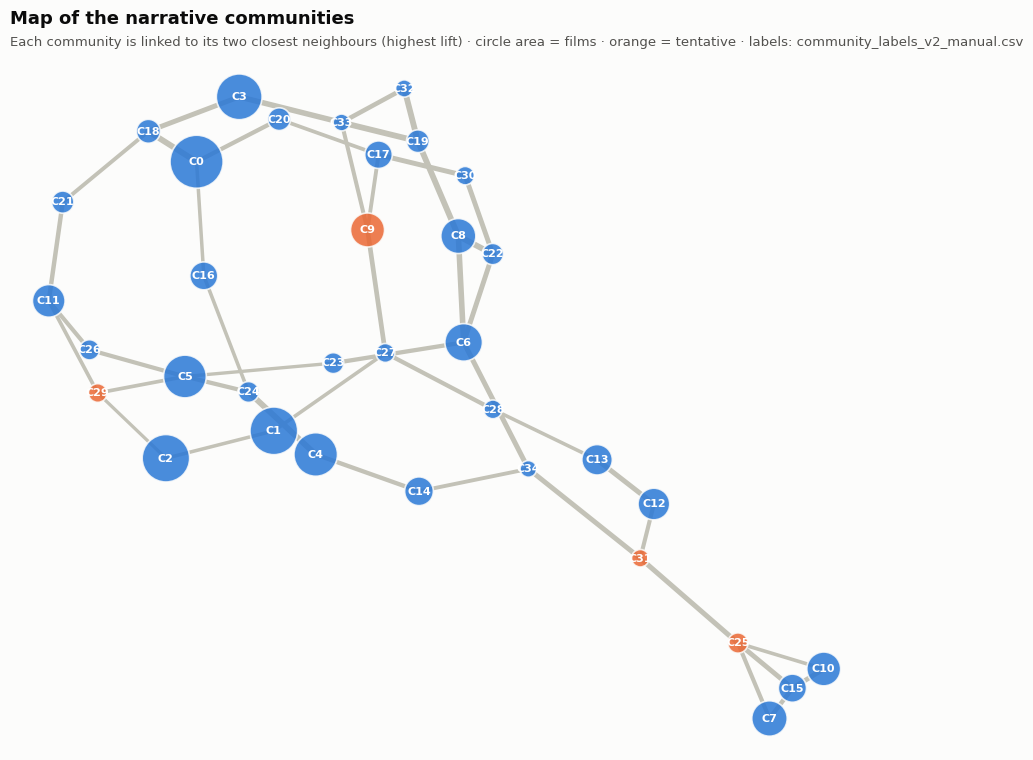

  ✓ figures/interpretation/fig_02_community_neighbourhood_map.png + tables/interpretation/fig_02_community_neighbourhood_map.csv


In [12]:
# ═══════════════════════════════════════════════════════════════════════════
# CELL 10 — Community adjacency (lift) + community map
# ═══════════════════════════════════════════════════════════════════════════
import networkx as nx
pair = pd.concat([e[["ca", "cb", "w"]], e[["cb", "ca", "w"]].set_axis(["ca", "cb", "w"], axis=1)])
W = pair.groupby(["ca", "cb"])["w"].sum().unstack(fill_value=0.0)
off_diag = ~np.eye(len(W), dtype=bool)
X_out = W.where(off_diag, 0.0)                # similarity leaving each community (internal similarity removed)
Xs = X_out.sum(axis=1)
lift = (X_out / np.outer(Xs, Xs) * Xs.sum()).where(off_diag)
ext_share = X_out.div(Xs, axis=0)

neighbours_long = (lift.stack().rename("lift").reset_index()
                   .rename(columns={"ca": "community_id", "cb": "neighbour_community"})
                   .merge(ext_share.stack().rename("share_of_external_similarity").reset_index()
                          .rename(columns={"ca": "community_id", "cb": "neighbour_community"}),
                          on=["community_id", "neighbour_community"])
                   .sort_values(["community_id", "share_of_external_similarity"], ascending=[True, False]))
save_new(neighbours_long.round(4), "community_neighbourhood_long.csv")
top_nb = (neighbours_long.groupby("community_id").head(3)
          .assign(s=lambda d: "C" + d["neighbour_community"].astype(str) + " ("
                  + (d["share_of_external_similarity"] * 100).round(0).astype(int).astype(str) + "%)")
          .groupby("community_id")["s"].agg("; ".join).rename("main_neighbour_communities"))
community_size_table = community_size_table.merge(top_nb, left_on="community_id", right_index=True, how="left")

# community map: major communities, each linked to its 2 strongest major neighbours (by lift)
nl = neighbours_long[neighbours_long["community_id"].isin(MAJOR) & neighbours_long["neighbour_community"].isin(MAJOR)]
links = nl.sort_values(["community_id", "lift"], ascending=[True, False]).groupby("community_id").head(2)
H = nx.Graph()
H.add_nodes_from(MAJOR)
for r in links.itertuples():
    H.add_edge(int(r.community_id), int(r.neighbour_community), lift=float(r.lift))
pos = nx.spring_layout(H, weight="lift", seed=42, k=1.6 / np.sqrt(len(MAJOR)), iterations=300)
fig, ax = plt.subplots(figsize=(11, 9))
for u, v, d in H.edges(data=True):
    ax.plot([pos[u][0], pos[v][0]], [pos[u][1], pos[v][1]], color=AXIS, linewidth=0.6 + 0.9 * min(d["lift"], 4), zorder=1)
xy = np.array([pos[c] for c in MAJOR])
area = 60 + 1400 * sizes[MAJOR].values / sizes[MAJOR].max()
tentative = (community_size_table.set_index("community_id").reindex(MAJOR)["tentative"].fillna(False).values
             if "tentative" in community_size_table else np.zeros(len(MAJOR), bool))
ax.scatter(xy[:, 0], xy[:, 1], s=area, color=np.where(tentative, SERIES[1], SERIES[0]), alpha=0.85,
           edgecolor=SURFACE, linewidth=1.2, zorder=2)
for c, (x_, y_) in zip(MAJOR, xy):
    ax.annotate(f"C{c}", (x_, y_), ha="center", va="center", fontsize=8, color="white", fontweight="bold", zorder=3)
ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
for sp in ax.spines.values():
    sp.set_visible(False)
ax.set_title("Map of the narrative communities")
subtitle(ax, "Each community is linked to its two closest neighbours (highest lift) · circle area = films · "
             "orange = tentative · labels: community_labels_v2_manual.csv")
save(fig, links.round(4), "fig_02_community_neighbourhood_map")


## 6. Labelling the communities

**How it works**
1. Notebook 03 matched the new communities to the ones you labelled before and wrote `community_labels_draft_v2.csv`.
2. This cell creates **`outputs/tables/community_labels_v2_manual.csv`** (once). Carried labels are pre-filled; every row carries the evidence above (key words, names, core films, genres, neighbours, robustness).
3. **You edit only that file:** fill or correct `suggested_label_manual`, optionally a `short_label` (≤ 30 characters, for figures) and `interpretation_note_manual`, and write `yes` in `label_reviewed`. Rows marked *carried* are already reviewed.
4. Re-run this notebook (from Cell 1, or just Cells 11–17). When every major community has a reviewed label, the file the bricks read — `community_manual_labeling_template_labeled.csv` — is written, in its fixed columns.

Re-running never overwrites what you typed; evidence columns are refreshed. If Notebook 03 is re-run and the communities change, your file is kept as `…_stale_<date>.csv` and a fresh one is started from the new carry-over.

In [13]:
# ═══════════════════════════════════════════════════════════════════════════
# CELL 11 — Labelling evidence per community (helper columns + evidence)
# ═══════════════════════════════════════════════════════════════════════════
def top_values_as_string(df, col, n):
    vc = df.groupby("community_id")[col].value_counts().groupby(level=0).head(n)
    return (vc.index.get_level_values(1).astype(str) + " (" + vc.astype(str).values + ")") \
             .to_series(index=vc.index.get_level_values(0)).groupby(level=0).agg("; ".join)

def titles_by(df, metric, n, ascending=False):
    """Top-n films per community by `metric`, one per title family, as 'Title (year)'."""
    t = (df.sort_values(["community_id", metric], ascending=[True, ascending])
           .drop_duplicates(["community_id", "title_family"]).groupby("community_id").head(n))
    lab = t["title"].astype(str) + " (" + t["release_year"].astype("Int64").astype(str) + ")"
    return lab.groupby(t["community_id"]).agg("; ".join)

CENTRAL = CFG["central_metric"]
nodes["_core_key"] = nodes["is_core"].astype(int) if CFG["core_first"] else 0
nodes["_central_key"] = nodes["_core_key"] * 1e6 + nodes[CENTRAL]       # core films first, then by centrality

helper = community_size_table[["community_id", "n_films", "share_of_network_pct"]].copy().set_index("community_id")
helper["top_primary_genres"] = top_values_as_string(nodes, "primary_genre", 6)
helper["median_year"] = community_size_table.set_index("community_id")["median_year"]
yr = nodes.groupby("community_id")["release_year"].agg(["min", "max"]).astype(int)
helper["year_range"] = yr["min"].astype(str) + "-" + yr["max"].astype(str)
for c in ["median_vote_count", "median_vote_average", "revenue_available_pct"]:
    helper[c] = community_size_table.set_index("community_id")[c]
helper["central_titles_weighted_degree"] = titles_by(nodes, "_central_key", 8)
helper["bridging_titles_betweenness"] = titles_by(nodes, BETW, 6)
helper["visible_titles_vote_count"] = titles_by(nodes, "vote_count", 8)
# new evidence
helper["core_exemplars_visible"] = titles_by(nodes[nodes["visible"]], "_central_key", 6)
helper["well_known_examples"] = titles_by(nodes[nodes["vote_count"] >= CFG["well_known_min_votes"]], "_central_key", 6)
helper = helper.join(key_terms.set_index("community_id").drop(columns=["top_name", "top_name_film_share"]))
helper["visible_titles_vote_count"] = helper["visible_titles_vote_count"]   # column kept as is
extra_cols = ["community_robustness", "core_share", "cohesion_internal_share", "top_genre_share",
              "main_neighbour_communities", "tentative", "largest_title_family", "largest_title_family_share",
              "top_name", "top_name_film_share", "franchise_driven", "name_driven"]
helper = helper.join(community_size_table.set_index("community_id")[[c for c in extra_cols if c in community_size_table]])
helper = helper.reset_index().sort_values("n_films", ascending=False).reset_index(drop=True)
helper.insert(0, "interpretation_priority", range(1, len(helper) + 1))
print("Columns:", list(helper.columns))
display(helper.head(10))
save_v1(helper.assign(suggested_label_manual="", interpretation_note_manual=""), "community_label_helper_v2_manual.csv")


Columns: ['interpretation_priority', 'community_id', 'n_films', 'share_of_network_pct', 'top_primary_genres', 'median_year', 'year_range', 'median_vote_count', 'median_vote_average', 'revenue_available_pct', 'central_titles_weighted_degree', 'bridging_titles_betweenness', 'visible_titles_vote_count', 'core_exemplars_visible', 'well_known_examples', 'key_terms', 'character_names', 'places', 'community_robustness', 'core_share', 'cohesion_internal_share', 'top_genre_share', 'main_neighbour_communities', 'tentative', 'largest_title_family', 'largest_title_family_share', 'top_name', 'top_name_film_share', 'franchise_driven', 'name_driven']


,interpretation_priority,community_id,n_films,share_of_network_pct,top_primary_genres,median_year,year_range,median_vote_count,median_vote_average,revenue_available_pct,central_titles_weighted_degree,bridging_titles_betweenness,visible_titles_vote_count,core_exemplars_visible,well_known_examples,key_terms,character_names,places,community_robustness,core_share,cohesion_internal_share,top_genre_share,main_neighbour_communities,tentative,largest_title_family,largest_title_family_share,top_name,top_name_film_share,franchise_driven,name_driven
0,1,0,1700,8.91,Action (448); Drama (312); Crime (270); Comedy (244); Thriller (189); Horror (102),2011.0,1990-2024,107.0,6.1000,41.18,The Postcard Killings (2020); Alex Cross (2012); Only the River Flows (2023); The Ghoul (2017); Bending Th...,Alone in the Dark (2005); The Rise (2012); A Beautiful Mind (2001); Milan – Palermo: The Return (2007); Th...,The Shawshank Redemption (1994); Se7en (1995); Spider-Man: No Way Home (2021); Ant-Man (2015); The Green M...,The Postcard Killings (2020); Alex Cross (2012); Only the River Flows (2023); Bending The Rules (2012); Fi...,Luther: The Fallen Sun (2023); Road to Perdition (2002); Double Jeopardy (1999); 21 Bridges (2019); Kraven...,police; prison; killer; murder; crime; cop; detective; case; man; gang; bank; officer,jack; john; frank; mike; ray; danny,hong; kong; angeles; los; york,0.669223,0.495882,0.735319,0.264,C1 (13%); C2 (11%); C3 (8%),False,fast_furious,0.003,jack,0.024,False,False
1,2,1,1360,7.13,Comedy (513); Drama (436); Romance (149); Thriller (63); Horror (53); Crime (35),2012.0,1990-2024,87.0,6.0000,40.07,Abraham's Valley (1993); The Other Woman (2010); Made of Honor (2008); Obsession (2019); Gabrielle (2005);...,Osman Pazarlama (2016); Bent (1997); Looking Glass (2018); Deadly Weekend (2013); Broken Sky (2006); The N...,Forrest Gump (1994); Get Out (2017); The Amazing Spider-Man (2012); Her (2013); The Devil Wears Prada (200...,The Other Woman (2010); Made of Honor (2008); Last Night (2010); Sweet November (2001); The Lovebirds (202...,Made of Honor (2008); Sweet November (2001); Something Borrowed (2011); The Hours (2002); Heartbeats (2010...,love; relationship; life; gay; wife; married; couple; man; woman; marriage; wedding; young,emily; paul; david; marie; sarah; max,york; american; angeles; london; los,0.596643,0.430147,0.690480,0.377,C2 (19%); C0 (13%); C7 (7%),False,bliss,0.002,emily,0.012,False,False
2,3,2,1346,7.05,Drama (495); Comedy (346); Horror (184); Thriller (82); Romance (48); Action (39),2014.0,1990-2024,88.5,6.1000,37.00,The House (2024); Pistas para volver a casa (2015); The Boogeyman (2023); Ghostland (2018); The Book of He...,Fist of Fury 1991 II (1992); Eternity and a Day (1998); Urban Explorer (2011); Soldier (1998); The Return ...,Spirited Away (2001); The Curious Case of Benjamin Button (2008); Prisoners (2013); Three Billboards Outsi...,The Boogeyman (2023); Ghostland (2018); The Book of Henry (2017); Glass House: The Good Mother (2006); Bea...,The Boogeyman (2023); Ghostland (2018); The Book of Henry (2017); House at the End of the Street (2012); A...,mother; family; father; old; year; son; brothers; home; life; brother; daughter; house,sarah; lola; alice; sam; laura; marie,york; american; london; tanya; angeles,0.516960,0.381129,0.677358,0.368,C1 (19%); C0 (12%); C5 (8%),False,alice,0.001,sarah,0.015,False,False
3,4,3,1246,6.53,Drama (451); Action (239); Comedy (130); War (125); Thriller (70); History (43),2013.0,1990-2024,95.5,6.3295,42.05,Sobibor (2018); The Auschwitz Report (2021); Aimée & Jaguar (1999); Leningrad (2009); Turbulence (1997); A...,"Mr. Kaplan (2014); Russendisko (2012); Mishmash, or Egg Nogg 3 (2019); The Edge (1997); Berlin Falling (20...",The Avengers (2012); Inglourious Basterds (2009); Dunkirk (2017); Saving Private Ryan (1998); Edge of Tomo...,Sobibor (2018); The Auschwitz Report (2021); Aimée & Jaguar (1999); Leningrad (2009); Turbulence (1997); A...,All Quiet on the Western Front (20

  ✓ tables/community_label_helper_v2_manual.csv


In [14]:
# ═══════════════════════════════════════════════════════════════════════════
# CELL 12 — Your labels file: create once, refresh evidence, keep what you typed
# ═══════════════════════════════════════════════════════════════════════════
USER_COLS = ["suggested_label_manual", "short_label", "interpretation_note_manual", "label_reviewed"]
EVIDENCE_COLS = ["n_films", "community_robustness", "tentative", "name_driven", "franchise_driven", "key_terms",
                 "character_names", "places", "well_known_examples", "core_exemplars_visible", "top_primary_genres",
                 "main_neighbour_communities"]

# starting point: NB03's carry-over draft (if any)
start = pd.DataFrame({"community_id": helper["community_id"]})
if DRAFT_FILE.exists():
    draft = pd.read_csv(DRAFT_FILE)
    keep = [c for c in ["community_id", "carryover_status", "matched_old_community", "jaccard",
                        "suggested_label_manual", "interpretation_note_manual"] if c in draft]
    start = start.merge(draft[keep].rename(columns={"suggested_label_manual": "carried_label"}), on="community_id", how="left")
    start["suggested_label_manual"] = start["carried_label"]
    start["label_reviewed"] = np.where(start["carryover_status"].eq("carried") & ~is_blank(start["carried_label"]), "yes", "")
    print("Carry-over draft found:", start["carryover_status"].value_counts().to_dict())
else:
    print("No carry-over draft (community_labels_draft_v2.csv) — every community starts unlabelled.")
    for c in ["carryover_status", "matched_old_community", "jaccard", "carried_label"]:
        start[c] = np.nan
for c in USER_COLS:
    if c not in start:
        start[c] = ""

fp_of = lambda df: df.get("partition_fingerprint", pd.Series([None])).iloc[0] if len(df) else None
existing = pd.read_csv(MANUAL_FILE) if MANUAL_FILE.exists() else None
if existing is None or fp_of(existing) != PARTITION_FP:      # an earlier file made for exactly these communities?
    for old_file in sorted(MANUAL_FILE.parent.glob(f"{MANUAL_FILE.stem}_stale_*.csv"), reverse=True):
        if fp_of(pd.read_csv(old_file)) == PARTITION_FP:
            if existing is not None:
                MANUAL_FILE.rename(MANUAL_FILE.with_name(f"{MANUAL_FILE.stem}_stale_{datetime.now():%Y%m%d_%H%M%S}.csv"))
            existing = pd.read_csv(old_file)
            print(f"Restored your labels from {old_file.name} (made for these same communities).")
            break
if existing is not None and fp_of(existing) != PARTITION_FP:
    stale = MANUAL_FILE.with_name(f"{MANUAL_FILE.stem}_stale_{datetime.now():%Y%m%d_%H%M%S}.csv")
    MANUAL_FILE.rename(stale)
    print(f"⚠ Your labels file belongs to a different set of communities (NB03 was re-run). "
          f"Kept as {stale.name}; starting a fresh one.")
    existing = None
if existing is not None:                      # keep what you typed, take everything else fresh
    typed = existing.set_index("community_id")[[c for c in USER_COLS if c in existing]]
    start = start.set_index("community_id")
    for c in typed.columns:
        start[c] = typed[c].reindex(start.index).where(~is_blank(typed[c].reindex(start.index)), start[c])
    start = start.reset_index()
    print("Existing labels file found — your entries are kept, evidence refreshed.")

labels = (start.merge(helper[["community_id"] + [c for c in EVIDENCE_COLS if c in helper]], on="community_id", how="left")
               .sort_values("n_films", ascending=False))
labels["is_major"] = labels["community_id"].isin(MAJOR)
labels["partition_fingerprint"] = PARTITION_FP
for c in USER_COLS + ["carried_label"]:
    labels[c] = labels[c].where(~is_blank(labels[c]), "")
labels["label_reviewed"] = labels["label_reviewed"].str.strip().str.lower()
norm_label = labels["suggested_label_manual"].str.strip().str.lower()
duplicate = labels["is_major"] & ~is_blank(labels["suggested_label_manual"]) & \
            norm_label.where(labels["is_major"]).duplicated(keep=False) & labels["is_major"]
labels["status"] = np.select(
    [is_blank(labels["suggested_label_manual"]), duplicate, labels["label_reviewed"].eq("yes")],
    ["needs label", "duplicate label", "ready"], default="needs review")
if duplicate.any():
    print("⚠ Several major communities carry the same label (an old community split in two). Give each its own label:",
          labels.loc[duplicate, "community_id"].tolist())
order_cols = (["community_id", "is_major", "status"] + USER_COLS[:1] + ["short_label", "label_reviewed",
              "interpretation_note_manual", "carryover_status", "matched_old_community", "jaccard", "carried_label"]
              + [c for c in EVIDENCE_COLS if c in labels] + ["partition_fingerprint"])
labels = labels[order_cols]
labels.to_csv(MANUAL_FILE, index=False)
print(f"  ✓ tables/{MANUAL_FILE.name}  ← edit this file")

major_status = labels[labels["is_major"]]["status"].value_counts()
print("\nMajor communities:", major_status.to_dict())
display(labels[labels["is_major"] & labels["status"].ne("ready")]
        [["community_id", "n_films", "status", "carryover_status", "carried_label", "key_terms",
          "well_known_examples"]].head(40))


Carry-over draft found: {'new': 101, 'carried – review': 3, 'carried': 1}
Existing labels file found — your entries are kept, evidence refreshed.
  ✓ tables/community_labels_v2_manual.csv  ← edit this file

Major communities: {'ready': 35}


,community_id,n_films,status,carryover_status,carried_label,key_terms,well_known_examples


In [15]:
# ═══════════════════════════════════════════════════════════════════════════
# CELL 13 — Template and the labelled file the bricks read
# ═══════════════════════════════════════════════════════════════════════════
V1_TEMPLATE_COLS = ["interpretation_priority", "community_id", "n_films", "share_of_network_pct", "top_primary_genres",
                    "year_range", "median_year", "median_vote_count", "median_vote_average", "revenue_available_pct",
                    "central_titles_weighted_degree", "bridging_titles_betweenness", "visible_titles_vote_count",
                    "suggested_label_manual", "interpretation_note_manual"]
NEW_TEMPLATE_COLS = ["short_label", "status", "carryover_status", "community_robustness", "tentative",
                     "name_driven", "franchise_driven", "key_terms", "character_names", "places",
                     "well_known_examples", "core_exemplars_visible", "main_neighbour_communities"]
template = (helper[helper["community_id"].isin(MAJOR)]
            .merge(labels[["community_id", "suggested_label_manual", "interpretation_note_manual", "short_label",
                           "status", "carryover_status"]], on="community_id", how="left"))
template["interpretation_priority"] = range(1, len(template) + 1)
template = template[V1_TEMPLATE_COLS + [c for c in NEW_TEMPLATE_COLS if c in template]]
save_v1(template, "community_manual_labeling_template.csv")
save_v1(template[["community_id", "n_films", "share_of_network_pct", "top_primary_genres",
                  "central_titles_weighted_degree", "visible_titles_vote_count", "suggested_label_manual"]
                 + [c for c in ["community_robustness", "key_terms"] if c in template]],
        "major_community_thesis_table.csv")

has_label = ~is_blank(template["suggested_label_manual"]) & template["status"].ne("duplicate label")
if CFG["accept_all_labels"] or not CFG["require_review_before_export"]:
    ready = has_label                       # you accepted every written label in one step
else:
    ready = template["status"].eq("ready")  # row by row: label written AND label_reviewed = yes
LABELS_COMPLETE = bool(ready.all())
if LABELS_COMPLETE:
    template.to_csv(LABELED_FILE, index=False)
    print(f"  ✓ tables/{LABELED_FILE.name} — all {len(template)} major communities labelled; the bricks can run.")
else:
    todo = template.loc[~ready, ["community_id", "status", "suggested_label_manual"]]
    no_label, dup = is_blank(todo["suggested_label_manual"]), todo["status"].eq("duplicate label")
    unreviewed = ~no_label & ~dup
    print(f"✗ {LABELED_FILE.name} NOT written yet — {len(todo)} of {len(template)} major communities are not confirmed:")
    if no_label.any():
        print(f"   • {int(no_label.sum())} have no label: write one in 'suggested_label_manual' "
              f"(communities {todo.loc[no_label, 'community_id'].tolist()})")
    if dup.any():
        print(f"   • {int(dup.sum())} share a label with another community: give each its own "
              f"(communities {todo.loc[dup, 'community_id'].tolist()})")
    if unreviewed.any():
        print(f"   • {int(unreviewed.sum())} have a label that is not confirmed yet. Either type yes in the "
              f"'label_reviewed' column of {MANUAL_FILE.name} for each row you accept,\n"
              f"     or, if you have read them all and accept them, set CFG['accept_all_labels'] = True in Cell 1. Then re-run.")
    if LABELED_FILE.exists():
        old = pd.read_csv(LABELED_FILE)
        same = (set(zip(old["community_id"], old["n_films"])) == set(zip(template["community_id"], template["n_films"])))
        if not same:
            print(f"⚠ The existing {LABELED_FILE.name} was made for an earlier network (different communities). "
                  "Do not run Notebook 05 or the bricks until labelling is finished — they would attach old labels "
                  "to new community ids.")

# label used in every table and figure below: your short label, else your label, else a placeholder
lab = labels.set_index("community_id")
display_label = lab["short_label"].where(~is_blank(lab["short_label"]), lab["suggested_label_manual"].map(lambda x: short(x) if x else ""))
display_label = display_label.where(~is_blank(display_label), "unlabelled")
nodes["community_label"] = nodes["community_id"].map(lab["suggested_label_manual"]).fillna("")
CLAB = {c: f"C{c} · {display_label.get(c, 'unlabelled')}" for c in sizes.index}


  ✓ tables/community_manual_labeling_template.csv
  ✓ tables/major_community_thesis_table.csv
  ✓ tables/community_manual_labeling_template_labeled.csv — all 35 major communities labelled; the bricks can run.


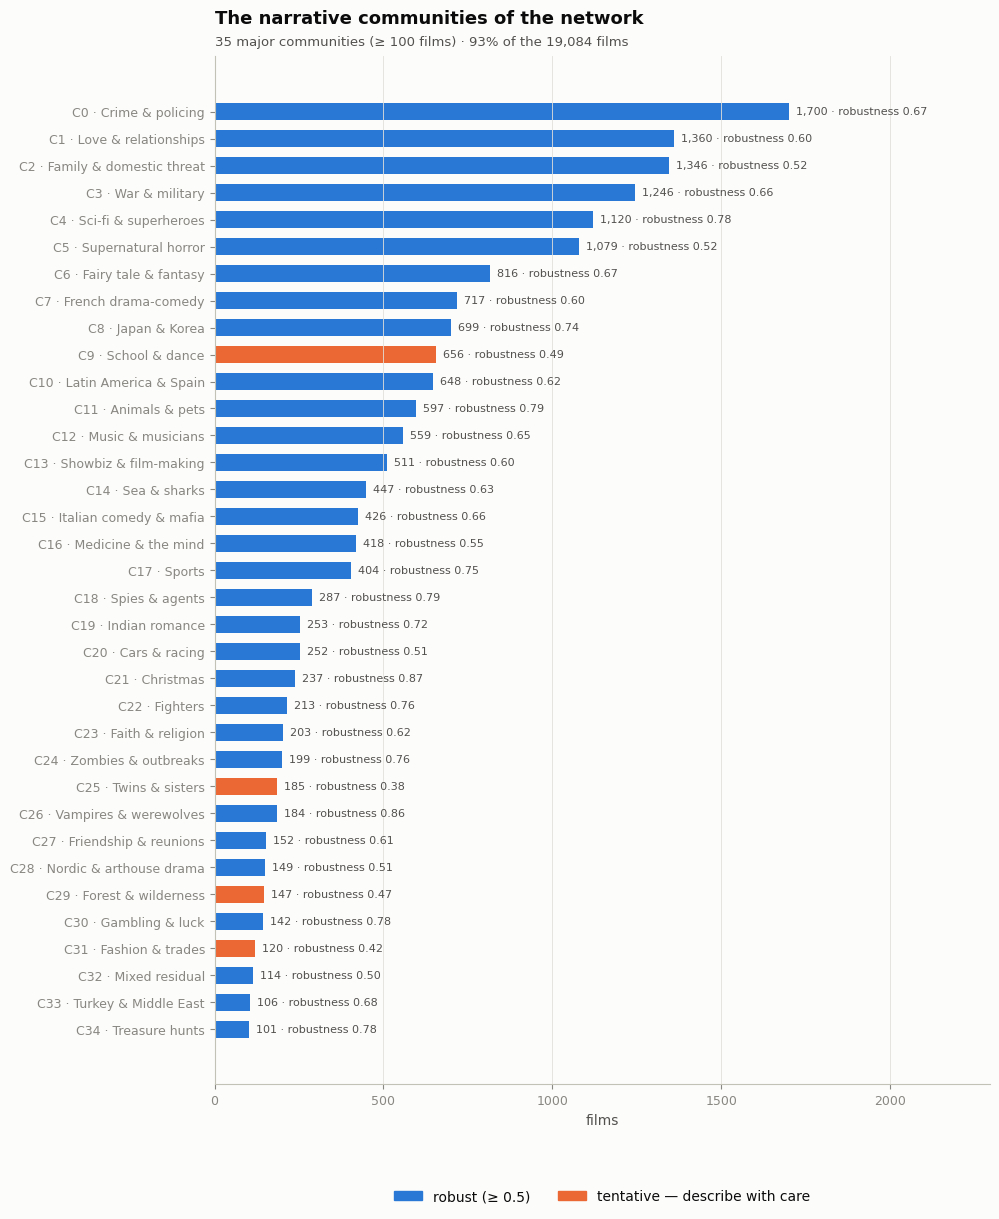

  ✓ figures/interpretation/fig_03_community_size_robustness.png + tables/interpretation/fig_03_community_size_robustness.csv  ✓ figures/top_20_communities_by_size.png


In [16]:
# ═══════════════════════════════════════════════════════════════════════════
# CELL 14 — Figure: community size and robustness
# ═══════════════════════════════════════════════════════════════════════════
t = community_size_table[community_size_table["is_major"]].copy()
t["label"] = t["community_id"].map(CLAB)
fig, ax = plt.subplots(figsize=(10, 0.33 * len(t) + 1.8))
y = np.arange(len(t))[::-1]
if HAS_CONF:
    colors = np.where(t["tentative"], SERIES[1], SERIES[0])
    ax.barh(y, t["n_films"], color=colors, height=0.62)
    for yi, (n, r) in zip(y, t[["n_films", "community_robustness"]].values):
        ax.text(n, yi, f"  {int(n):,} · robustness {r:.2f}", va="center", fontsize=8, color=INK_2)
    from matplotlib.patches import Patch
    ax.legend(handles=[Patch(color=SERIES[0], label=f"robust (≥ {CFG['tentative_robustness']})"),
                       Patch(color=SERIES[1], label="tentative — describe with care")],
              loc="upper center", bbox_to_anchor=(0.5, -0.09), ncol=2)
else:
    ax.barh(y, t["n_films"], color=SERIES[0], height=0.62)
ax.set_yticks(y, t["label"])
ax.set_xlabel("films")
ax.set_xlim(0, t["n_films"].max() * 1.35)
ax.grid(axis="y", visible=False)
ax.set_title("The narrative communities of the network")
subtitle(ax, f"{len(t)} major communities (≥ {CFG['min_community_size_for_interpretation']} films) · "
             f"{t['n_films'].sum() / len(nodes):.0%} of the {len(nodes):,} films")
save(fig, t.drop(columns=["label"]), "fig_03_community_size_robustness", also_v1="top_20_communities_by_size.png")


## 7. Central films

Global tables use the standard definitions (weighted degree, exact betweenness, PageRank). Per community, representative films are ranked by **within-community strength**, core films first (`CFG['central_metric']`). All example tables apply the display rules: at least 50 votes and one film per title family (the network itself is never changed).

In [17]:
# ═══════════════════════════════════════════════════════════════════════════
# CELL 15 — Global centrality tables (new columns at the end)
# ═══════════════════════════════════════════════════════════════════════════
V1_COLS = ["title", "release_year", "primary_genre", "vote_count", "vote_average", "community_id", "degree",
           "weighted_degree", "pagerank", "betweenness_centrality_sampled", "eigenvector_centrality", "clustering_coefficient"]
NEW_COLS = ["betweenness_centrality", "membership_confidence", "within_community_strength",
            "participation_coefficient", "community_label", "title_family"]
def compact(df):
    return df[[c for c in V1_COLS + NEW_COLS if c in df.columns]].copy()

def top_unique(df, metric, n):
    return df.sort_values(metric, ascending=False).drop_duplicates("title_family").head(n)

N = CFG["top_n_global"]
vis = nodes[nodes["visible"]]
tables = {
    "top_weighted_degree_raw.csv":                      compact(nodes.sort_values("weighted_degree", ascending=False).head(N)),
    "top_weighted_degree_franchise_capped.csv":         compact(top_unique(nodes, "weighted_degree", N)),
    "top_betweenness_franchise_capped.csv":             compact(top_unique(nodes, BETW, N)),
    "top_pagerank_franchise_capped.csv":                compact(top_unique(nodes, "pagerank", N)),
    "top_weighted_degree_visible_franchise_capped.csv": compact(top_unique(vis, "weighted_degree", N)),
    "top_betweenness_visible_franchise_capped.csv":     compact(top_unique(vis, BETW, N)),
    "top_pagerank_visible_franchise_capped.csv":        compact(top_unique(vis, "pagerank", N)),
}
for name, t in tables.items():
    save_v1(t, name)
raw = tables["top_weighted_degree_raw.csv"]
print(f"\nFranchise effect: the raw top-{N} by weighted degree holds {raw['title_family'].nunique()} distinct title families "
      f"({N - raw['title_family'].nunique()} rows are repeats of the same franchise).")
display(tables["top_weighted_degree_visible_franchise_capped.csv"].head(15))


  ✓ tables/top_weighted_degree_raw.csv
  ✓ tables/top_weighted_degree_franchise_capped.csv
  ✓ tables/top_betweenness_franchise_capped.csv
  ✓ tables/top_pagerank_franchise_capped.csv
  ✓ tables/top_weighted_degree_visible_franchise_capped.csv
  ✓ tables/top_betweenness_visible_franchise_capped.csv
  ✓ tables/top_pagerank_visible_franchise_capped.csv

Franchise effect: the raw top-50 by weighted degree holds 46 distinct title families (4 rows are repeats of the same franchise).


,title,release_year,primary_genre,vote_count,vote_average,community_id,degree,weighted_degree,pagerank,betweenness_centrality_sampled,eigenvector_centrality,clustering_coefficient,betweenness_centrality,membership_confidence,within_community_strength,participation_coefficient,community_label,title_family
4995,The Return,2006,Horror,650.0,6.000,16,20,14.142814,0.000098,0.000271,0.000102,0.125210,0.000271,0.564,11.374085,0.343628,"Hospitals, illness, memory and the mind",the return
15246,The Postcard Killings,2020,Drama,647.0,6.340,0,20,14.034301,0.000102,0.000193,0.000173,0.193618,0.000193,0.789,14.034301,0.000000,"Crime, policing and the criminal underworld",postcard killings
8043,Beautiful Kate,2009,Drama,68.0,5.600,2,20,13.925760,0.000101,0.000394,0.000091,0.112787,0.000394,0.632,12.536324,0.184614,"Family secrets, siblings and domestic threat",beautiful kate
5721,Glass House: The Good Mother,2006,Drama,91.0,5.600,2,20,13.909829,0.000095,0.000286,0.000116,0.103107,0.000286,0.646,12.537676,0.182694,"Family secrets, siblings and domestic threat",glass house good mother
10241,All That Glitters,2010,Comedy,756.0,6.350,27,20,13.840334,0.000112,0.000261,0.000025,0.230400,0.000261,0.759,11.839811,0.256464,"Friend groups, reunions and getaways",all that glitters
11774,Kite,2014,Drama,270.0,4.300,0,20,13.806968,0.000094,0.000407,0.000110,0.079657,0.000407,0.755,8.982131,0.524320,"Crime, policing and the criminal underworld",kite
6774,The Kindred,2021,Horror,125.0,6.400,2,20,13.802756,0.000108,0.000498,0.000081,0.072492,0.000498,0.655,12.405356,0.187098,"Family secrets, siblings and domestic threat",kindred
1153,Bad Company,1995,Action,69.0,4.942,18,20,13.781380,0.000098,0.000110,0.000116,0.253537,0.000110,0.885,13.781380,0.000000,"Espionage, secret agents, terrorism and hackers",bad company
2952,The Salton Sea,2002,Crime,348.0,6.565,1,20,13.740104,0.000093,0.000440,0.000100,0.082551,0.000440,0.308,6.872375,0.646503,"Romance, marriage and relationship drama-comedy",salton sea
3284,Scooby-Doo,2002,Mystery,4744.0,6.099,41,20,13.653917,0.000076,0.000041,0.249147,0.450180,0.000041,0.978,13.653917,0.000000,,scooby_doo


In [18]:
# ═══════════════════════════════════════════════════════════════════════════
# CELL 16 — Representative films per community (one sort + groupby, no loops)
# ═══════════════════════════════════════════════════════════════════════════
def per_community(df, key, n):
    t = (df.sort_values(["community_id", key], ascending=[True, False])
           .drop_duplicates(["community_id", "title_family"]).groupby("community_id").head(n).copy())
    t["rank"] = t.groupby("community_id").cumcount() + 1
    return t

KEEP = ["community_id", "title", "release_year", "primary_genre", "vote_count", "vote_average", "weighted_degree",
        "betweenness_centrality_sampled", "pagerank"]
KEEP_NEW = ["within_community_strength", "membership_confidence", "is_core", "participation_coefficient", "community_label"]
KEEP_NEW = [c for c in KEEP_NEW if c in nodes]

top_central = per_community(vis, "_central_key", CFG["top_n_per_community_display"]) \
    .rename(columns={"rank": "rank_within_community"})
top_central = (top_central[["community_id", "rank_within_community"] + KEEP[1:] + KEEP_NEW]
               .merge(community_size_table[["community_id", "n_films", "top_genre"]], on="community_id", how="left")
               .sort_values(["n_films", "community_id", "rank_within_community"], ascending=[False, True, True]))
top_central = top_central[[c for c in top_central if c not in KEEP_NEW] + KEEP_NEW]   # stable order, new columns last
save_v1(top_central, "top_visible_central_films_per_community.csv")

n = CFG["top_n_per_community"]
major_nodes = nodes[nodes["community_id"].isin(MAJOR)]
reps = pd.concat([
    per_community(major_nodes, "_central_key", n).assign(selection_type="central_within_community"),
    per_community(major_nodes, BETW, n).assign(selection_type="bridging_betweenness"),
    per_community(major_nodes, "vote_count", n).assign(selection_type="visible_examples"),
], ignore_index=True)
reps = reps[["community_id", "selection_type", "rank"] + KEEP[1:] + KEEP_NEW]
save_v1(reps, "community_representative_films_long.csv")

show = top_central[top_central["community_id"].isin(MAJOR[:8])]
display(show[["community_id", "rank_within_community", "title", "release_year", "vote_count"]
             + [c for c in ["membership_confidence", "community_label"] if c in show]])


  ✓ tables/top_visible_central_films_per_community.csv
  ✓ tables/community_representative_films_long.csv


,community_id,rank_within_community,title,release_year,vote_count,membership_confidence,community_label
0,0,1,The Postcard Killings,2020,647.0,0.789,"Crime, policing and the criminal underworld"
1,0,2,Alex Cross,2012,767.0,0.789,"Crime, policing and the criminal underworld"
2,0,3,Only the River Flows,2023,107.0,0.789,"Crime, policing and the criminal underworld"
3,1,1,The Other Woman,2010,415.0,0.753,"Romance, marriage and relationship drama-comedy"
4,1,2,Made of Honor,2008,1772.0,0.760,"Romance, marriage and relationship drama-comedy"
5,1,3,Last Night,2010,816.0,0.760,"Romance, marriage and relationship drama-comedy"
6,2,1,The Boogeyman,2023,1062.0,0.655,"Family secrets, siblings and domestic threat"
7,2,2,Ghostland,2018,2631.0,0.655,"Family secrets, siblings and domestic threat"
8,2,3,The Book of Henry,2017,1349.0,0.622,"Family secrets, siblings and domestic threat"
9,3,1,Sobibor,2018,325.0,0.788,"War, historical conflict and military action"


## 8. Bridge films

Exact betweenness ranks films that lie on many shortest paths between other films. The **participation coefficient** says whether that is because the film's own neighbours are spread across communities (a true crossover plot) or because it links two otherwise separate areas through a few edges. Each bridge is listed with the two communities it connects.

  ✓ tables/bridging_films_betweenness.csv


,title,release_year,vote_count,betweenness_centrality,participation_coefficient,bridges_between
18688,Black Panther: Wakanda Forever,2022,7422.0,0.002203,0.755393,"C8 · Japanese and Korean cinema: samurai, yakuza, school life and anime ↔ C6 · Fairy tales, royalty and ..."
4278,Alone in the Dark,2005,654.0,0.001987,0.661311,"C0 · Crime, policing and the criminal underworld ↔ C9 · School, campus and dance coming-of-age"
11494,The Last Days,2013,375.0,0.001976,0.507006,"C24 · Zombies, viruses and outbreaks ↔ C16 · Hospitals, illness, memory and the mind"
7733,Dune,2021,14779.0,0.001931,0.445430,"C4 · Science fiction, space, robots and superhero worlds ↔ C6 · Fairy tales, royalty and mythic fantasy"
13205,Mr. Kaplan,2014,26.0,0.001923,0.741554,"C3 · War, historical conflict and military action ↔ C7 · French relationship and family drama-comedy"
326,Fist of Fury 1991 II,1992,31.0,0.001905,0.747195,"C2 · Family secrets, siblings and domestic threat ↔ C0 · Crime, policing and the criminal underworld"
17388,The Ciambra,2017,172.0,0.001871,0.845504,"C20 · Cars, racing and road journeys ↔ C2 · Family secrets, siblings and domestic threat"
10449,Russendisko,2012,57.0,0.001829,0.491101,"C3 · War, historical conflict and military action ↔ C27 · Friend groups, reunions and getaways"
18182,Shoplifters,2018,2273.0,0.001787,0.277319,"C8 · Japanese and Korean cinema: samurai, yakuza, school life and anime ↔ C15 · Italian comedy, family a..."
14549,Casa Grande,2014,123.0,0.001754,0.690958,"C10 · Latin American and Spanish-language drama ↔ C15 · Italian comedy, family and the mafia"


Community pairs joined by the most top bridges:


,bridges
C3 ↔ C7,4
C4 ↔ C5,4
C6 ↔ C8,3
C4 ↔ C6,3
C3 ↔ C10,2
C1 ↔ C28,2
C2 ↔ C19,2
C8 ↔ C28,2
C10 ↔ C15,2
C17 ↔ C20,2


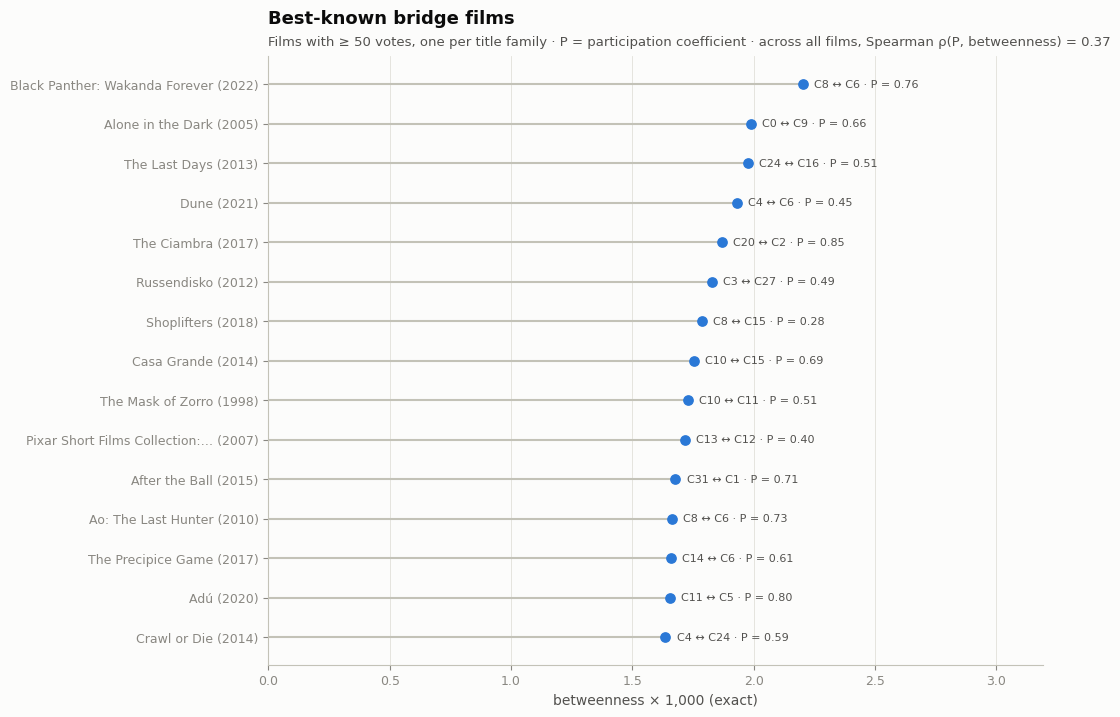

  ✓ figures/interpretation/fig_04_bridges_participation.png + tables/interpretation/fig_04_bridges_participation.csv


In [19]:
# ═══════════════════════════════════════════════════════════════════════════
# CELL 17 — Bridging films (with the communities each bridge joins) and a figure
# ═══════════════════════════════════════════════════════════════════════════
b = top_unique(nodes, BETW, CFG["top_n_bridges"])
bridges = compact(b).join(b[["main_external_community", "external_share"]])
full = {c: f"C{c} · {lab['suggested_label_manual'].get(c, '') or 'unlabelled'}" for c in sizes.index}
bridges["bridges_between"] = (bridges["community_id"].map(full) + "  ↔  "
                              + bridges["main_external_community"].map(lambda c: full.get(c, "—") if pd.notna(c) else "—"))
save_v1(bridges, "bridging_films_betweenness.csv")
display(bridges[["title", "release_year", "vote_count", BETW, "participation_coefficient", "bridges_between"]].head(15))

bp = bridges.dropna(subset=["main_external_community"])
lo = np.minimum(bp["community_id"], bp["main_external_community"].astype(int))
hi = np.maximum(bp["community_id"], bp["main_external_community"].astype(int))
pairs = ("C" + lo.astype(str) + " ↔ C" + hi.astype(str)).value_counts().head(10)
print("Community pairs joined by the most top bridges:"); display(pairs.to_frame("bridges"))

rho = nodes[["participation_coefficient", BETW]].corr(method="spearman").iloc[0, 1]
# figure: the best-known bridge films (≥ display_min_vote_count votes), with the two communities they join
tb = (vis.dropna(subset=["main_external_community"]).sort_values(BETW, ascending=False)
         .drop_duplicates("title_family").head(15).iloc[::-1])
fig, ax = plt.subplots(figsize=(10, 0.42 * len(tb) + 1.6))
y = np.arange(len(tb))
ax.hlines(y, 0, tb[BETW] * 1e3, color=AXIS, linewidth=1.5)
ax.scatter(tb[BETW] * 1e3, y, s=45, color=SERIES[0], zorder=3)
for yi, r in zip(y, tb.itertuples()):
    ax.annotate(f"C{r.community_id} ↔ C{int(r.main_external_community)} · P = {r.participation_coefficient:.2f}",
                (getattr(r, BETW) * 1e3, yi), xytext=(8, 0), textcoords="offset points", va="center",
                fontsize=8, color=INK_2)
ax.set_yticks(y, [f"{short(t, 34)} ({int(yr)})" for t, yr in zip(tb["title"], tb["release_year"])])
ax.set_xlim(0, tb[BETW].max() * 1e3 * 1.45)
ax.set_xlabel("betweenness × 1,000 (exact)" if BETW == "betweenness_centrality" else "betweenness × 1,000 (sampled)")
ax.grid(axis="y", visible=False)
ax.set_title("Best-known bridge films")
subtitle(ax, f"Films with ≥ {CFG['display_min_vote_count']} votes, one per title family · P = participation coefficient · "
             f"across all films, Spearman ρ(P, betweenness) = {rho:.2f}")
save(fig, tb[["title", "release_year", "community_id", "main_external_community", "participation_coefficient", BETW]],
     "fig_04_bridges_participation")


In [20]:
# ═══════════════════════════════════════════════════════════════════════════
# CELL 18 — Peripheral films (with confidence) and boundary films
# ═══════════════════════════════════════════════════════════════════════════
PCOLS = ["title", "release_year", "primary_genre", "vote_count", "vote_average", "community_id", "degree",
         "weighted_degree", "clustering_coefficient"] + [c for c in ["membership_confidence", "community_label"] if c in nodes]
peripheral = (vis.sort_values(["degree", "weighted_degree", "clustering_coefficient"])[PCOLS].head(CFG["n_peripheral"]))
save_v1(peripheral, "peripheral_films_candidates.csv")
print("Peripheral = few, weak plot neighbours. Not 'bad' films — semantically unusual ones.")
display(peripheral.head(10))

if HAS_CONF:
    print(f"Boundary films (in their community in < {CFG['boundary_confidence']:.0%} of single runs): "
          f"{int(nodes['is_boundary'].sum()):,} ({nodes['is_boundary'].mean():.1%})")
    boundary = (vis[vis["community_id"].isin(MAJOR)].sort_values("membership_confidence")
                [["title", "release_year", "vote_count", "community_id", "membership_confidence",
                  "main_external_community", "participation_coefficient", "community_label"]].head(50))
    save_new(boundary, "boundary_films_low_confidence.csv")
    print("Well-known boundary films (communities disagree across runs):"); display(boundary.head(10))


  ✓ tables/peripheral_films_candidates.csv
Peripheral = few, weak plot neighbours. Not 'bad' films — semantically unusual ones.


,title,release_year,primary_genre,vote_count,vote_average,community_id,degree,weighted_degree,clustering_coefficient,membership_confidence,community_label
17212,Newton,2017,Comedy,147.0,7.100,19,1,0.341531,0.0,0.836,"Indian romance, marriage and family"
6440,George Carlin: It's Bad for Ya!,2008,Comedy,139.0,7.900,12,1,0.347371,0.0,0.642,"Music, bands and performers' careers"
11129,Nitro Circus: The Movie,2012,Action,118.0,6.300,4,1,0.353959,0.0,0.874,"Science fiction, space, robots and superhero worlds"
7357,24 City,2008,Drama,60.0,7.000,5,1,0.363040,0.0,0.507,"Supernatural horror: hauntings, demons and possession"
11801,Postman Pat: The Movie,2014,Family,52.0,5.100,11,1,0.368655,0.0,0.876,Animals and pets: family animal adventures
3393,The Navigators,2001,Drama,82.0,6.900,12,1,0.379382,0.0,0.441,"Music, bands and performers' careers"
8178,Three Monkeys,2008,Drama,221.0,6.800,11,1,0.382538,0.0,0.861,Animals and pets: family animal adventures
6469,Bring It On: In It to Win It,2007,Comedy,531.0,6.447,12,1,0.382878,0.0,0.798,"Music, bands and performers' careers"
14123,Pride,2014,Drama,1381.0,7.700,3,1,0.384485,0.0,0.510,"War, historical conflict and military action"
5339,Piranha 3D,2010,Comedy,2378.0,5.400,4,1,0.384858,0.0,0.831,"Science fiction, space, robots and superhero worlds"


Boundary films (in their community in < 20% of single runs): 260 (1.4%)
  ✓ tables/interpretation/boundary_films_low_confidence.csv
Well-known boundary films (communities disagree across runs):


,title,release_year,vote_count,community_id,membership_confidence,main_external_community,participation_coefficient,community_label
9548,Parallel,2024,65.0,14,0.009,2,0.748976,"The sea: ships, sharks, pirates and island survival"
11984,Handling the Undead,2024,161.0,2,0.010,16,0.664922,"Family secrets, siblings and domestic threat"
7526,Mum & Dad,2008,137.0,0,0.013,2,0.812643,"Crime, policing and the criminal underworld"
16963,White Noise,2022,788.0,4,0.013,2,0.748983,"Science fiction, space, robots and superhero worlds"
18554,Freaks,2019,1257.0,1,0.017,14,0.857052,"Romance, marriage and relationship drama-comedy"
3276,Yamakasi,2001,592.0,14,0.018,10,0.438262,"The sea: ships, sharks, pirates and island survival"
4042,The Great Challenge,2004,96.0,14,0.018,10,0.494612,"The sea: ships, sharks, pirates and island survival"
3981,Shopgirl,2005,275.0,5,0.019,6,0.622409,"Supernatural horror: hauntings, demons and possession"
1714,The Castle,1997,222.0,7,0.021,0,0.497793,French relationship and family drama-comedy
5663,Suburbicon,2017,1799.0,2,0.029,7,0.749824,"Family secrets, siblings and domestic threat"


## 8b. Minor communities

Communities below the size threshold are not labelled one by one. They are described together here, so the thesis can say what they are (many are franchise or character clusters), and Notebook 05 can pool them into a single **minor** group (`community_group` in `processed/network/node_positions_nb04.csv`) instead of fitting dozens of tiny dummies.

In [21]:
# ═══════════════════════════════════════════════════════════════════════════
# CELL 18b — Minor communities summary
# ═══════════════════════════════════════════════════════════════════════════
minor = community_size_table[~community_size_table["is_major"]].copy()
if len(minor):
    minor["visible_examples"] = minor["community_id"].map(titles_by(nodes, "vote_count", 5))
    minor["key_terms"] = minor["community_id"].map(key_terms.set_index("community_id")["key_terms"])
    cols = ["community_id", "n_films", "top_genre", "visible_examples", "key_terms", "largest_title_family",
            "largest_title_family_share", "top_name", "top_name_film_share", "franchise_or_name_driven",
            "main_neighbour_communities"] + [c for c in ["community_robustness"] if c in minor]
    minor = minor[cols]
    print(f"{len(minor)} minor communities hold {minor['n_films'].sum():,} films ({minor['n_films'].sum() / len(nodes):.1%}); "
          f"{int(minor['franchise_or_name_driven'].sum())} of them are franchise/name-driven.")
    display(minor.head(20))
    save_new(minor, "minor_communities.csv")
else:
    print("No minor communities.")


70 minor communities hold 1,291 films (6.8%); 11 of them are franchise/name-driven.


,community_id,n_films,top_genre,visible_examples,key_terms,largest_title_family,largest_title_family_share,top_name,top_name_film_share,franchise_or_name_driven,main_neighbour_communities,community_robustness
35,35,87,Western,John Wick: Chapter 3 - Parabellum (2019); Back to the Future Part III (1990); The Magnificent Seven (2016)...,bounty; outlaw; west; hunter; gunslinger; guts; town; hunters; marshal; sheriff; gang; farmer,,0.000,griffith,0.023,False,C0 (26%); C4 (8%); C3 (7%),0.808724
36,36,82,Comedy,The Founder (2016); What Women Want (2000); Chef (2014); Burnt (2015); Dinner for Schmucks (2010),chef; restaurant; food; cook; kitchen; culinary; waitress; michelin; executive; chess; pizza; cuisine,chef,0.024,annie,0.037,False,C1 (22%); C2 (13%); C7 (7%),0.711037
37,37,79,Drama,Shaun of the Dead (2004); Maze Runner: The Death Cure (2018); Unstoppable (2010); The Ninth Gate (1999); T...,recep; train; subway; maze; club; tyler; avery; tunnel; electrical; red; tunnels; race,recep ivedik,0.051,rory,0.025,False,C3 (15%); C5 (10%); C4 (7%),0.431266
38,38,76,Drama,"Law Abiding Citizen (2009); Me, Myself & Irene (2000); Primal Fear (1996); Cape Fear (1991); The Lincoln L...",lawyer; case; judge; accused; attorney; trial; jury; court; firm; defense; murder; matters,accused,0.026,charlie,0.039,False,C0 (34%); C2 (11%); C16 (7%),0.828592
39,39,73,Drama,Black Panther (2018); Men in Black: International (2019); Ghostbusters: Afterlife (2021); Aquaman and the ...,wine; chip; panther; black; returns; home; brother; years; pearl; son; father; mother,black panther,0.027,martin,0.425,True,C2 (14%); C0 (10%); C3 (10%),0.712986
40,40,45,Drama,Fifty Shades of Grey (2015); Fifty Shades Freed (2018); Fifty Shades Darker (2017); The Last Airbender (20...,water; marriage; grey; past; couple; guests; sexual; party; memories; woman; life; mythology,path,0.044,ana,0.644,True,C1 (18%); C10 (12%); C2 (9%),0.879844
41,41,41,Animation,Scooby-Doo (2002); Rite Here Rite Now (2024); The Wizard of Gore (2007); Supernatural Activity (2012); App...,scooby; doo; mystery; gang; velma; ghost; spooky; solve; ghoul; fun; crew; vampire,scooby_doo,0.902,shaggy,0.537,True,C4 (29%); C5 (24%); C11 (14%),0.959854
42,42,39,Drama,"Jumanji (1995); Chronicle (2012); Zathura: A Space Adventure (2005); South Park: Bigger, Longer & Uncut (1...",park; amusement; kids; siblings; games; game; school; theme; toys; children; stumble; appearance,,0.000,sam,0.051,False,C5 (17%); C2 (10%); C6 (8%),0.531923
43,43,37,Horror,Wrong Turn 2: Dead End (2007); Jackass Number Two (2006); The Fifth Estate (2013); The Curse of the Jade S...,online; contestants; volume; media; social; youtube; reality; internet; prize; random; ass; influencer,,0.000,knoxville,0.081,False,C5 (18%); C13 (15%); C30 (8%),0.834838
44,44,36,Drama,Scary Movie 4 (2006); Ghosts of Girlfriends Past (2009); Polaroid (2019); The Valet (2022); Jackass Presen...,photographer; camera; photo; christina; erotic; photographing; printing; love; grief; sophie; photos; nikki,,0.000,connor,0.028,False,C1 (14%); C5 (14%); C7 (11%),0.683056


  ✓ tables/interpretation/minor_communities.csv


## 9. Reception by community (descriptive only)

A first look at whether communities differ in rating and revenue. This is **not** the success model — that is Notebook 05, with controls for year, genre and visibility. The Kruskal–Wallis ε² effect size says how much of the variation lies between communities (0 = none, 1 = all).

  ✓ tables/community_outcome_summary_descriptive.csv


,outcome,films,H,p_value,epsilon_squared
0,vote_average,17793,867.7,2.949256e-160,0.047
1,log_revenue,7072,400.3,4.066345e-64,0.052
2,popularity,17793,520.2,2.413802e-88,0.027


  ✓ tables/interpretation/community_outcome_effect_sizes.csv


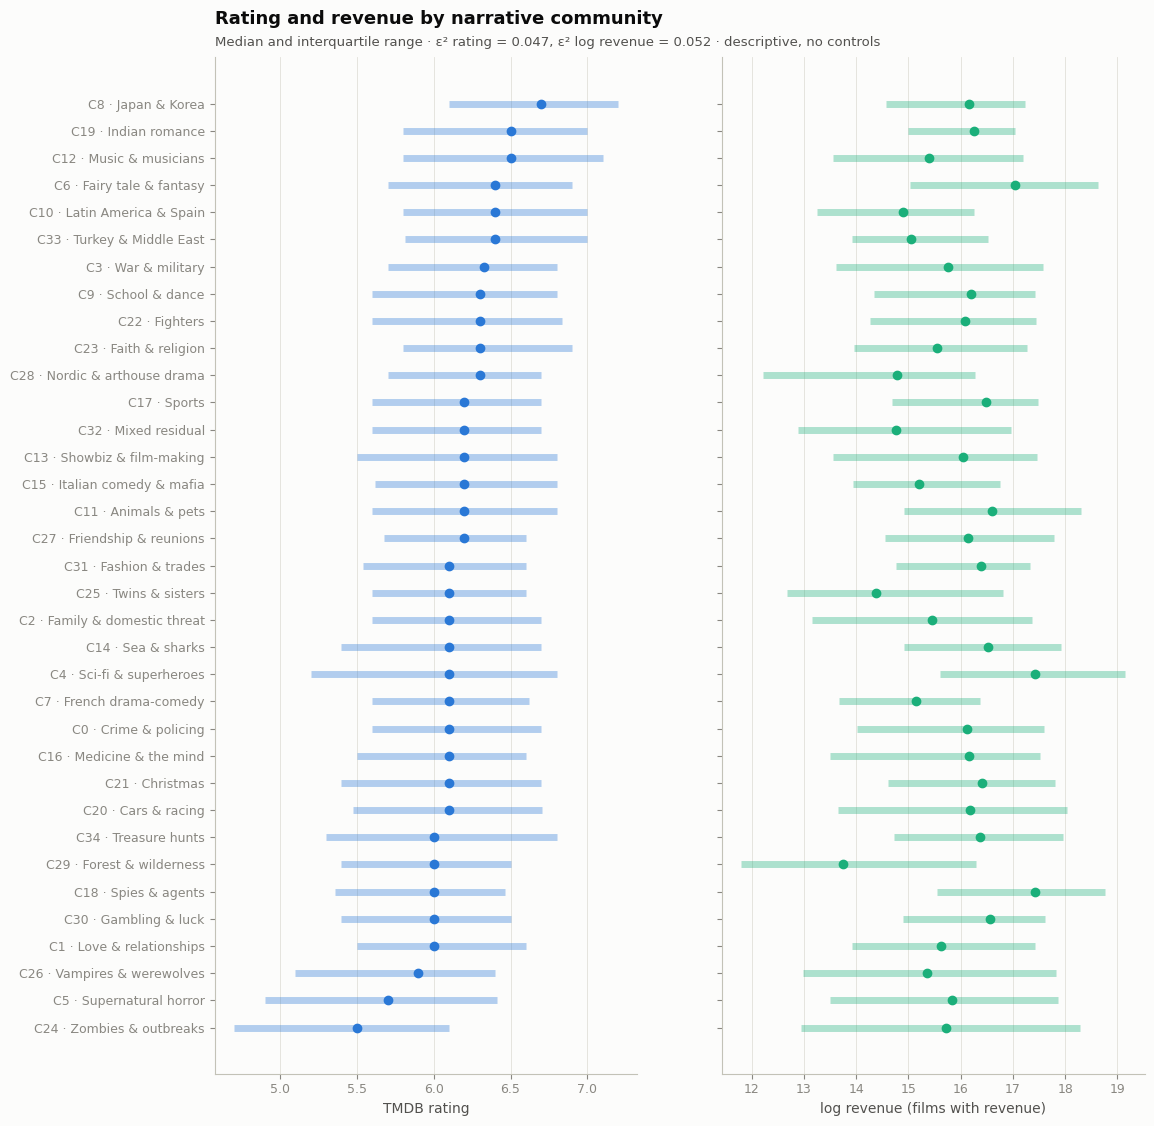

  ✓ figures/interpretation/fig_05_reception_by_community.png + tables/interpretation/fig_05_reception_by_community.csv


In [22]:
# ═══════════════════════════════════════════════════════════════════════════
# CELL 19 — Community outcome summary + effect sizes + figure
# ═══════════════════════════════════════════════════════════════════════════
community_outcome_summary = (nodes.groupby("community_id")
    .agg(n_films=("node_id", "count"),
         revenue_available_pct=("revenue_clean", lambda x: round(x.notna().mean() * 100, 2)),
         median_revenue=("revenue_clean", "median"), mean_log_revenue=("log_revenue", "mean"),
         median_vote_average=("vote_average", "median"), median_vote_count=("vote_count", "median"),
         median_popularity=("popularity", "median"), median_weighted_degree=("weighted_degree", "median"),
         median_betweenness=(BETW, "median"))
    .reset_index().sort_values("n_films", ascending=False))
community_outcome_summary["community_label"] = community_outcome_summary["community_id"].map(lab["suggested_label_manual"])
if HAS_CONF:
    community_outcome_summary["community_robustness"] = community_outcome_summary["community_id"].map(
        community_size_table.set_index("community_id")["community_robustness"])
save_v1(community_outcome_summary, "community_outcome_summary_descriptive.csv")

def kw(col):
    d = nodes[nodes["community_id"].isin(MAJOR)].dropna(subset=[col])
    groups = [x[col].values for _, x in d.groupby("community_id")]
    H, pval = kruskal(*groups)
    return {"outcome": col, "films": len(d), "H": round(H, 1), "p_value": pval,
            "epsilon_squared": round((H - len(groups) + 1) / (len(d) - len(groups)), 3)}
effects = pd.DataFrame([kw(c) for c in ["vote_average", "log_revenue", "popularity"] if c in nodes])
display(effects)
save_new(effects, "community_outcome_effect_sizes.csv")

d = nodes[nodes["community_id"].isin(MAJOR)]
q = d.groupby("community_id").agg(r50=("vote_average", "median"), r25=("vote_average", lambda x: x.quantile(.25)),
                                   r75=("vote_average", lambda x: x.quantile(.75)), v50=("log_revenue", "median"),
                                   v25=("log_revenue", lambda x: x.quantile(.25)), v75=("log_revenue", lambda x: x.quantile(.75)),
                                   rev_n=("log_revenue", "count")).sort_values("r50")
fig, axes = plt.subplots(1, 2, figsize=(12, 0.32 * len(q) + 2), sharey=True)
y = np.arange(len(q))
for ax, (m, lo, hi, color, xl) in zip(axes, [("r50", "r25", "r75", SERIES[0], "TMDB rating"),
                                              ("v50", "v25", "v75", SERIES[2], "log revenue (films with revenue)")]):
    ax.hlines(y, q[lo], q[hi], color=color, alpha=0.35, linewidth=5)
    ax.plot(q[m], y, "o", color=color)
    ax.set_xlabel(xl)
    ax.grid(axis="y", visible=False)
axes[0].set_yticks(y, [CLAB[c] for c in q.index])
eps = effects.set_index("outcome")["epsilon_squared"]
axes[0].set_title("Rating and revenue by narrative community")
subtitle(axes[0], f"Median and interquartile range · ε² rating = {eps.get('vote_average', np.nan):.3f}, "
                  f"ε² log revenue = {eps.get('log_revenue', np.nan):.3f} · descriptive, no controls")
save(fig, q.reset_index(), "fig_05_reception_by_community")


In [23]:
# ═══════════════════════════════════════════════════════════════════════════
# CELL 20 — Interpretation notes (written from the numbers; claims appear only if the data supports them)
# ═══════════════════════════════════════════════════════════════════════════
nmi = genre_vs_comm.loc[0, "NMI"]
lines = [
    "Network interpretation notes",
    "",
    f"The semantic network contains {len(nodes):,} films in its largest connected component and {len(edges):,} "
    "mutual-kNN similarity edges. Edges represent similarity between plot overviews, not success, fame or quality.",
    f"Community detection ({audit.get('community_method', 'see network_audit.csv')}) finds {nodes['community_id'].nunique()} "
    f"communities; {len(MAJOR)} have at least {CFG['min_community_size_for_interpretation']} films and cover "
    f"{sizes[MAJOR].sum() / len(nodes):.1%} of the network. {e['internal'].mean():.1%} of edges lie inside a community.",
]
if HAS_CONF:
    tent = community_size_table[community_size_table["is_major"] & community_size_table["tentative"]]
    lines.append(f"Membership confidence (share of single Louvain runs that keep a film with its consensus community): "
                 f"median {nodes['membership_confidence'].median():.2f}; {nodes['is_boundary'].mean():.1%} of films are "
                 f"boundary films (< {CFG['boundary_confidence']}). {nodes['is_core'].mean():.0%} of films are core films "
                 f"(≥ {CFG['core_internal_share']:.0%} of their similarity inside their community). "
                 + (f"{len(tent)} major {'community is' if len(tent) == 1 else 'communities are'} tentative (robustness < {CFG['tentative_robustness']}): "
                    f"{', '.join('C' + tent['community_id'].astype(str))}; describe {'its' if len(tent) == 1 else 'their'} boundaries as blurred."
                    if len(tent) else "All major communities are robust."))
lines.append(f"NMI between community and primary genre is {nmi:.2f} (chance level {genre_vs_comm.loc[2, 'NMI']:.2f}). "
             + ("Communities overlap little with primary-genre labels (part of this gap reflects that a single primary "
                "genre is a coarse label); several communities are thematic (crime, war, sci-fi, school) across genres."
                if nmi < 0.25 else
                "Communities partly follow genre lines but are not reducible to them."
                if nmi < 0.5 else "Communities follow genre lines closely; the plot-based grouping largely restates genre."))
cst = community_size_table
lines.append(f"{len(MAJOR)} communities are labelled; the other {len(sizes) - len(MAJOR)} minor communities hold "
             f"{sizes.drop(MAJOR).sum() / len(nodes):.1%} of films and are pooled as 'minor'. "
             f"{int(cst['franchise_driven'].sum())} communities are franchise-driven and {int(cst['name_driven'].sum())} "
             f"character-name-driven ({int((cst['name_driven'] & cst['is_major']).sum())} of them major).")
if name_edges is not None:
    nv = name_edges.set_index("measure")["value"]
    lines.append(f"{nv.iloc[0]:.1%} of edges join two films whose overviews share a character name "
                 f"({nv.iloc[2]:.0f}× the chance level of {nv.iloc[1]:.2%}). "
                 + (("Person names were masked before embedding, so this residue comes mostly from franchise sequels "
                     "and names the recogniser missed." if "masked" in str(audit.get("embedded_text_column", "")) else
                     "Proper names therefore pull films together independently of plot; masking names before embedding "
                     "(Notebook 03) is recommended.") if nv.iloc[2] >= 3 else "Names play only a minor role in the edges."))
if change is not None:
    cv = change.set_index("measure")["value"]
    lines.append(f"Compared with the previous network (before the current Notebook 03 settings), community agreement is "
                 f"ARI {cv.get('ARI previous vs current (films in both)')}; {int(float(cv.get('films that left the network'))):,} films left "
                 f"the largest component." + (f" Films of the previous name-driven communities now stay together at a mean "
                 f"share of {cv.get('… mean share of their films still together in one community')}."
                 if '… mean share of their films still together in one community' in cv else ""))
lines.append("Weighted degree is bounded by k = 20 neighbours, so the most 'central' films are those whose overviews "
             "are most generic (similar to many others); they are typical, not influential, films.")
lines.append(f"Betweenness is {'exact' if BETW == 'betweenness_centrality' else 'sampled (approximate)'}. "
             f"Spearman correlation between participation coefficient and betweenness: {rho:.2f}.")
lines.append(f"The raw top-{N} by weighted degree contains {raw['title_family'].nunique()} distinct title families; "
             "thesis tables therefore apply a display-only franchise cap and a 50-vote visibility rule.")
if len(effects):
    lines.append("Descriptive differences in reception between major communities (Kruskal–Wallis ε²): "
                 + ", ".join(f"{r.outcome} {r.epsilon_squared:.3f}" for r in effects.itertuples())
                 + ". Formal modelling with controls follows in Notebook 05.")
lines.append(f"Labels: {int(major_status.get('ready', 0))} of {len(MAJOR)} major communities have reviewed labels"
             + ("." if LABELS_COMPLETE else f"; the labelled file for the bricks is not yet written."))
notes = "\n".join(lines)
(TABLES_DIR / "network_interpretation_notes.txt").write_text(notes, encoding="utf-8")
print(notes)
print("\n  ✓ tables/network_interpretation_notes.txt")


Network interpretation notes

The semantic network contains 19,084 films in its largest connected component and 70,252 mutual-kNN similarity edges. Edges represent similarity between plot overviews, not success, fame or quality.
Community detection (consensus_louvain_igraph) finds 105 communities; 35 have at least 100 films and cover 93.2% of the network. 69.3% of edges lie inside a community.
Membership confidence (share of single Louvain runs that keep a film with its consensus community): median 0.68; 1.4% of films are boundary films (< 0.2). 45% of films are core films (≥ 75% of their similarity inside their community). 4 major communities are tentative (robustness < 0.5): C9, C25, C29, C31; describe their boundaries as blurred.
NMI between community and primary genre is 0.11 (chance level 0.01). Communities overlap little with primary-genre labels (part of this gap reflects that a single primary genre is a coarse label); several communities are thematic (crime, war, sci-fi, school

In [24]:
# ═══════════════════════════════════════════════════════════════════════════
# CELL 21 — Output check
# ═══════════════════════════════════════════════════════════════════════════
brick_inputs = ["top_visible_central_films_per_community.csv", "top_weighted_degree_raw.csv",
                "top_weighted_degree_franchise_capped.csv", "top_weighted_degree_visible_franchise_capped.csv",
                "top_betweenness_visible_franchise_capped.csv", "bridging_films_betweenness.csv",
                LABELED_FILE.name]
other_v1 = ["network_interpretation_basic_checks.csv", "remaining_event_like_titles_check.csv",
            "community_size_overview.csv", "franchise_concentration_diagnostic.csv",
            "top_betweenness_franchise_capped.csv", "top_pagerank_franchise_capped.csv",
            "top_pagerank_visible_franchise_capped.csv", "community_representative_films_long.csv",
            "community_label_helper_v2_manual.csv", "community_manual_labeling_template.csv",
            "major_community_thesis_table.csv", "peripheral_films_candidates.csv",
            "community_outcome_summary_descriptive.csv", "network_interpretation_notes.txt", MANUAL_FILE.name]
rows = [{"file": f, "group": "read by bricks", "exists": (TABLES_DIR / f).exists()} for f in brick_inputs]
rows += [{"file": f, "group": "bricks table", "exists": (TABLES_DIR / f).exists()} for f in other_v1]
rows += [{"file": f"interpretation/{p.name}", "group": "new", "exists": True} for p in sorted(INT_TABLES.glob("*.csv"))]
rows += [{"file": f"figures/interpretation/{p.name}", "group": "new figure", "exists": True} for p in sorted(INT_FIGS.glob("*.png"))]
out = pd.DataFrame(rows)
display(out)
if not LABELS_COMPLETE:
    print(f"Next: open {MANUAL_FILE.name}, label the rows marked 'needs label' / 'needs review', set label_reviewed = yes, re-run.")


,file,group,exists
0,top_visible_central_films_per_community.csv,read by bricks,True
1,top_weighted_degree_raw.csv,read by bricks,True
2,top_weighted_degree_franchise_capped.csv,read by bricks,True
3,top_weighted_degree_visible_franchise_capped.csv,read by bricks,True
4,top_betweenness_visible_franchise_capped.csv,read by bricks,True
5,bridging_films_betweenness.csv,read by bricks,True
6,community_manual_labeling_template_labeled.csv,read by bricks,True
7,network_interpretation_basic_checks.csv,v1 table,True
8,remaining_event_like_titles_check.csv,v1 table,True
9,community_size_overview.csv,v1 table,True


## What comes next

* **Finish the labels** in `community_labels_v2_manual.csv` until Cell 13 reports that the labelled file was written. Use `key_terms`, `core_exemplars_visible` and `carried_label` together; for *tentative* communities choose a broad label.
* Then **Notebook 05** (success and star power): it reads the labels, `membership_confidence`, exact betweenness and — from `processed/network/node_positions_nb04.csv` — the participation coefficient.
* For the Results chapter: Figure 1 (genre composition + NMI) answers "are these just genres?", Figure 2 is the map of narrative neighbourhoods, Figure 4 describes bridge films.